# Segmentación de clientes de comercio electrónico mediante técnicas de clustering

## 1. Introducción

En el sector del comercio electrónico, comprender el comportamiento de compra de los clientes es fundamental para diseñar estrategias de marketing, fidelización y retención. Sin embargo, las empresas suelen manejar grandes volúmenes de transacciones que dificultan identificar patrones de comportamiento mediante análisis tradicionales.

Este proyecto propone utilizar técnicas de aprendizaje automático no supervisado para identificar segmentos de clientes con características de compra similares, utilizando el conjunto de datos Online Retail de UCI Machine Learning Repository.

Se implementarán y compararán dos algoritmos de clustering: K-Means y Gaussian Mixture Models (GMM). Se realizarán procesos de limpieza de datos, ingeniería y selección de características, optimización de hiperparámetros, validación cruzada repetida y comparación estadística de los modelos.

### Objetivo general
Identificar y analizar grupos de clientes con comportamientos de compra similares mediante técnicas de clustering, determinando cuál de los algoritmos estudiados proporciona una segmentación más adecuada según métricas de validación interna y criterios estadísticos.

### Objetivos específicos
- Analizar la calidad, estructura y distribución de los datos transaccionales.
- Construir variables representativas del comportamiento de compra mediante el enfoque RFM.
- Implementar pipelines de preprocesamiento y clustering.
- Optimizar los hiperparámetros de K-Means y GMM.
- Comparar estadísticamente el desempeño de ambas técnicas.
- Visualizar los segmentos mediante t-SNE e interpretar sus características comerciales.

### Pregunta de investigación
¿Cuál de los algoritmos, K-Means o Gaussian Mixture Models, permite identificar segmentos de clientes más consistentes y diferenciados a partir de su comportamiento de compra?

### Consideración metodológica
El dataset no contiene etiquetas verdaderas de segmentos; por tanto, métricas supervisadas como accuracy no son pertinentes. Los segmentos descubiertos requieren interpretación comercial y no representan categorías previamente verificadas.

### 2. Descripción de los datos

El conjunto de datos Online Retail registra las transacciones de un comercio electrónico sin tienda física establecido en el Reino Unido. Según UCI, su cobertura es del 1 de diciembre de 2010 al 9 de diciembre de 2011, con 541.909 filas y 8 columnas en el archivo original. La empresa comercializa principalmente regalos; una parte de sus compradores son mayoristas.

**Unidad de análisis original:** línea de factura o transacción, no cliente. Un cliente puede aparecer en muchas filas e incluso una factura puede tener varios productos. Antes del clustering se agruparán las transacciones a nivel de CustomerID.

**Aspectos a investigar:** identificadores faltantes, duplicados, cancelaciones, cantidades no positivas, precios no positivos, distribución temporal, concentración geográfica, importes extremos y número de clientes identificables. Se deben calcular los resultados sobre los datos leídos y no asumirlos únicamente por la ficha del repositorio.

### 3. Análisis exploratorio de datos (EDA)

### 3.1. Librerías y configuración

In [ ]:
from pathlib import Path
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Python:", sys.version.split()[0])
print("Sistema:", platform.system())
print("Ejecutable:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn se utilizará en la siguiente etapa.")

Python: 3.13.5
Sistema: Windows
Ejecutable: c:\Users\Asus\Desktop\Maestria\MachineLearning\online-retail-clustering\.venv\Scripts\python.exe
Pandas: 3.0.6
Scikit-learn se utilizará en la siguiente etapa.


### 3.2. Carga y verificación del dataset

In [53]:
# Compatible con notebooks ubicados en la raíz del proyecto o en notebooks/.
posibles_rutas = [
    Path("data/raw/Online Retail.xlsx"),
    Path("../data/raw/Online Retail.xlsx"),
]
ruta_dataset = next((ruta for ruta in posibles_rutas if ruta.is_file()), None)
if ruta_dataset is None:
    raise FileNotFoundError(
        "Coloca 'Online Retail.xlsx' dentro de data/raw/ y ejecuta el notebook "
        "desde la raíz del proyecto o desde la carpeta notebooks/."
    )

df = pd.read_excel(ruta_dataset, engine="openpyxl")
columnas_esperadas = {
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
}
faltantes_en_archivo = columnas_esperadas - set(df.columns)
if faltantes_en_archivo:
    raise ValueError(f"Faltan columnas esperadas: {faltantes_en_archivo}")

# Conversión de tipos para las operaciones exploratorias (sin descartar filas).
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
for columna in ["Quantity", "UnitPrice"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

print(f"Archivo: {ruta_dataset.resolve()}")
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
display(df.head(10))

Archivo: C:\Users\Asus\Desktop\Maestria\MachineLearning\online-retail-clustering\data\raw\Online Retail.xlsx
Filas: 541,909 | Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,"17,850.00",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,"17,850.00",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,"13,047.00",United Kingdom


### 3.3. Estructura, tipos de datos y cardinalidad

In [ ]:
print("--- Información general ---")
df.info(show_counts=True)

print("\n--- Resumen de columnas ---")
resumen_columnas = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(dropna=True),
})
resumen_columnas["porcentaje_nulos"] = (resumen_columnas["nulos"] / len(df) * 100).round(2)
display(resumen_columnas)

print("\nRango de fechas:", df["InvoiceDate"].min(), "a", df["InvoiceDate"].max())

--- Información general ---
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

--- Resumen de columnas ---


,tipo,no_nulos,nulos,unicos,porcentaje_nulos
InvoiceNo,object,541909,0,25900,0.00
StockCode,object,541909,0,4070,0.00
Description,object,540455,1454,4223,0.27
Quantity,int64,541909,0,722,0.00
InvoiceDate,datetime64[us],541909,0,23260,0.00
UnitPrice,float64,541909,0,1630,0.00
CustomerID,float64,406829,135080,4372,24.93
Country,str,541909,0,38,0.00



Rango de fechas: 2010-12-01 08:26:00 a 2011-12-09 12:50:00


### 3.4. Calidad de los registros

La exploración de calidad permitirá fundamentar las reglas de preparación posteriores. Una factura marcada como cancelada puede no ser equivalente a una compra efectiva; asimismo, no se podrá construir el perfil de un cliente si falta su identificador.

,Cantidad
Filas totales,541909
Filas duplicadas exactas,5268
CustomerID faltante,135080
Description faltante,1454
InvoiceDate faltante/no convertible,0
Facturas marcadas C (líneas),9288
Quantity negativa,10624
Quantity igual a 0,0
UnitPrice negativo,2
UnitPrice igual a 0,2515


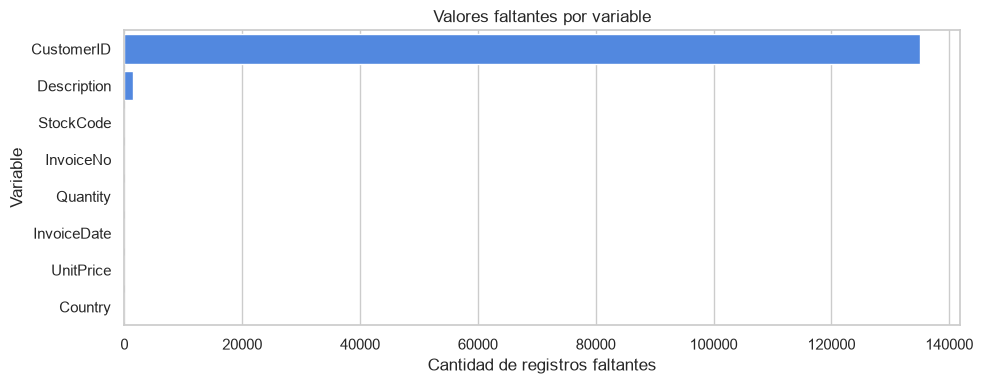

In [ ]:
# El prefijo C identifica cancelaciones de acuerdo con la documentación original.
es_cancelacion = (
    df["InvoiceNo"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

indicadores_calidad = pd.Series({
    "Filas totales": len(df),
    "Filas duplicadas exactas": int(df.duplicated().sum()),
    "CustomerID faltante": int(df["CustomerID"].isna().sum()),
    "Description faltante": int(df["Description"].isna().sum()),
    "InvoiceDate faltante/no convertible": int(df["InvoiceDate"].isna().sum()),
    "Facturas marcadas C (líneas)": int(es_cancelacion.sum()),
    "Quantity negativa": int((df["Quantity"] < 0).sum()),
    "Quantity igual a 0": int((df["Quantity"] == 0).sum()),
    "UnitPrice negativo": int((df["UnitPrice"] < 0).sum()),
    "UnitPrice igual a 0": int((df["UnitPrice"] == 0).sum()),
})
display(indicadores_calidad.to_frame("Cantidad"))

faltantes = df.isna().sum().sort_values(ascending=False)
if faltantes.sum() > 0:
    plt.figure(figsize=(10, 4))
    sns.barplot(x=faltantes.values, y=faltantes.index, color="#3B82F6")
    plt.title("Valores faltantes por variable")
    plt.xlabel("Cantidad de registros faltantes")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()
else:
    print("No se han detectado valores nulos en las columnas originales.")

### 3.5. Estadística descriptiva de variables numéricas

In [ ]:
columnas_numericas = ["Quantity", "UnitPrice"]
resumen_numerico = df[columnas_numericas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
display(resumen_numerico)

print("\nConteos importantes (sin agregación):")
print("Clientes identificados:", f"{df['CustomerID'].nunique(dropna=True):,}")
print("Facturas distintas:", f"{df['InvoiceNo'].nunique(dropna=True):,}")
print("Productos distintos:", f"{df['StockCode'].nunique(dropna=True):,}")
print("Países distintos:", f"{df['Country'].nunique(dropna=True):,}")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",-2.00,1.00,1.00,3.00,10.00,29.00,100.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",0.19,0.42,1.25,2.08,4.13,9.95,18.00,"38,970.00"



Conteos importantes (sin agregación):
Clientes identificados: 4,372
Facturas distintas: 25,900
Productos distintos: 4,070
Países distintos: 38


### 3.6. Vista provisional de compras positivas

Para analizar volumen y evolución de compras se crea una vista provisional con cantidades y precios positivos, fechas disponibles y facturas no marcadas como canceladas. Esta selección no modifica df y no constituye todavía la limpieza definitiva. No se excluyen por ahora los registros sin CustomerID de la estadística general de ventas, pero sí del análisis a nivel de cliente.
El importe por línea se define como: Quantity × UnitPrice (libras esterlinas). Es una aproximación a ventas brutas de las líneas seleccionadas, no beneficio ni ventas netas de devoluciones.

In [ ]:
mascara_compra = (
    df["Quantity"].gt(0)
    & df["UnitPrice"].gt(0)
    & df["InvoiceDate"].notna()
    & ~es_cancelacion
)

ventas_validas = df.loc[mascara_compra].copy()
ventas_validas["ImporteLinea"] = (
    ventas_validas["Quantity"] * ventas_validas["UnitPrice"]
)
ventas_validas["Mes"] = ventas_validas["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

ventas_clientes = ventas_validas.loc[ventas_validas["CustomerID"].notna()].copy()

print("Filas originales:", f"{len(df):,}")
print("Líneas positivas y no canceladas:", f"{len(ventas_validas):,}")
print("Líneas con cliente identificable:", f"{len(ventas_clientes):,}")
print("Clientes en la vista:", f"{ventas_clientes['CustomerID'].nunique():,}")
print("Importe bruto provisional (£):", f"{ventas_validas['ImporteLinea'].sum():,.2f}")
display(ventas_validas.head(5))

Filas originales: 541,909
Líneas positivas y no canceladas: 530,104
Líneas con cliente identificable: 397,884
Clientes en la vista: 4,338
Importe bruto provisional (£): 10,666,684.54


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ImporteLinea,Mes
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01


### 3.7. Evolución mensual de las ventas

Se visualizan la suma de importes positivos y el número de facturas únicas de la vista provisional. Los meses inicial y final pueden ser incompletos debido a la cobertura del dataset; no deben compararse sin considerar esa limitación temporal.

,Mes,ImporteBruto,Facturas
0,2010-12-01,"823,746.14",1559
1,2011-01-01,"691,364.56",1086
2,2011-02-01,"523,631.89",1100
3,2011-03-01,"717,639.36",1454
4,2011-04-01,"537,808.62",1246
5,2011-05-01,"770,536.02",1681
6,2011-06-01,"761,739.90",1533
7,2011-07-01,"719,221.19",1475
8,2011-08-01,"759,138.38",1361
9,2011-09-01,"1,058,590.17",1837


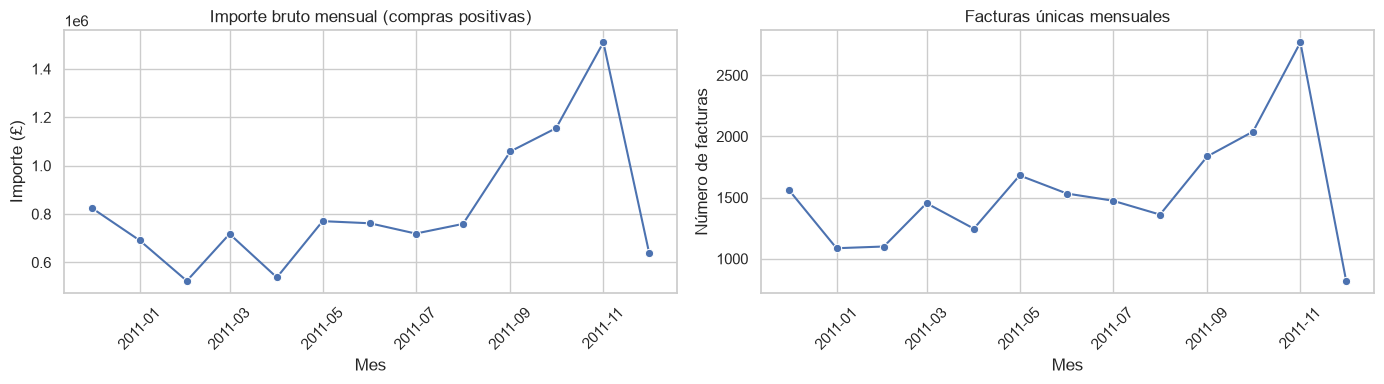

In [ ]:
mensual = (
    ventas_validas.groupby("Mes", as_index=False)
    .agg(ImporteBruto=("ImporteLinea", "sum"), Facturas=("InvoiceNo", "nunique"))
    .sort_values("Mes")
)
display(mensual)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=mensual, x="Mes", y="ImporteBruto", marker="o", ax=axes[0])
axes[0].set(title="Importe bruto mensual (compras positivas)", xlabel="Mes", ylabel="Importe (£)")
axes[0].tick_params(axis="x", rotation=45)
sns.lineplot(data=mensual, x="Mes", y="Facturas", marker="o", ax=axes[1])
axes[1].set(title="Facturas únicas mensuales", xlabel="Mes", ylabel="Número de facturas")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 3.8. Distribución geográfica de clientes identificados

,Clientes,Facturas
Country,,
United Kingdom,3920,16646
Germany,94,457
France,87,389
Spain,30,90
Belgium,25,98
Switzerland,21,51
Portugal,19,57
Italy,14,38
Finland,12,41


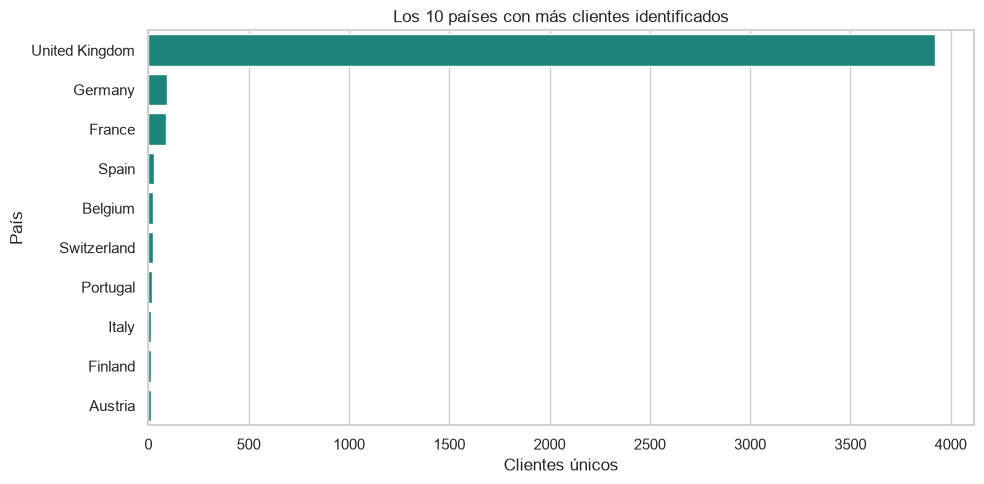

In [ ]:
paises = (
    ventas_clientes.groupby("Country", dropna=False)
    .agg(Clientes=("CustomerID", "nunique"), Facturas=("InvoiceNo", "nunique"))
    .sort_values("Clientes", ascending=False)
)
display(paises.head(10))

plt.figure(figsize=(10, 5))
sns.barplot(x=paises.head(10)["Clientes"], y=paises.head(10).index, color="#0D9488")
plt.title("Los 10 países con más clientes identificados")
plt.xlabel("Clientes únicos")
plt.ylabel("País")
plt.tight_layout()
plt.show()

### 3.9. Distribuciones y posibles valores atípicos

Las distribuciones de compra pueden presentar asimetría: muchos pedidos pequeños y unas pocas operaciones de gran magnitud. Se aplica log1p (solo para visualizar) a cantidades, precios e importes positivos. Esto no sustituye la transformación que se decida implementar en el pipeline posterior.

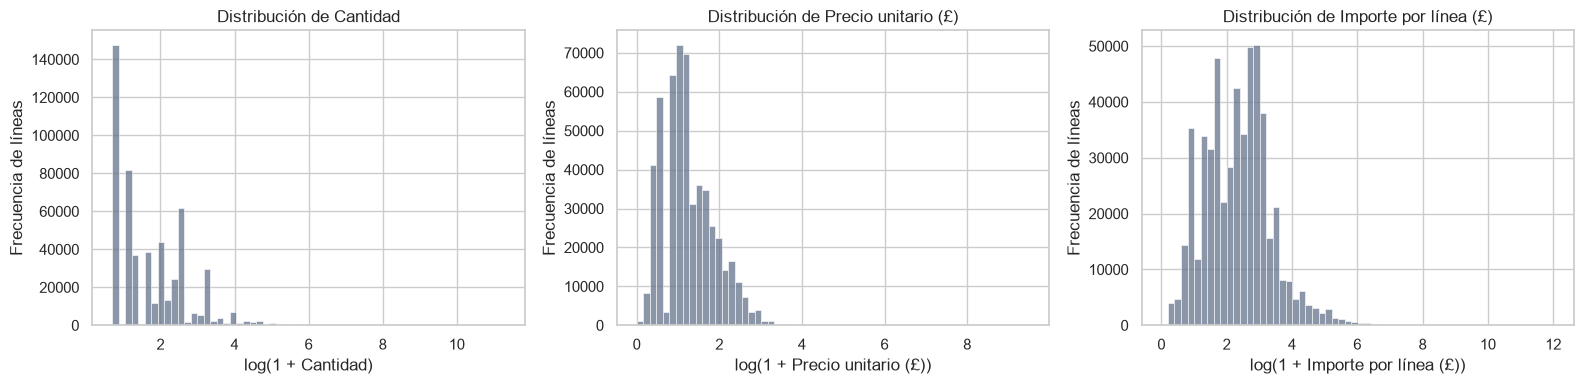

Percentiles de los importes por línea (compras positivas):


,Importe (£)
0.50,9.90
0.75,17.70
0.95,59.70
0.99,183.60
1.00,835.20


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
variables = [
    ("Quantity", "Cantidad"),
    ("UnitPrice", "Precio unitario (£)"),
    ("ImporteLinea", "Importe por línea (£)"),
]
for ax, (col, nombre) in zip(axes, variables):
    valores = np.log1p(ventas_validas[col].dropna())
    sns.histplot(valores, bins=60, ax=ax, color="#64748B")
    ax.set_title(f"Distribución de {nombre}")
    ax.set_xlabel(f"log(1 + {nombre})")
    ax.set_ylabel("Frecuencia de líneas")
plt.tight_layout()
plt.show()

print("Percentiles de los importes por línea (compras positivas):")
display(ventas_validas["ImporteLinea"].quantile([0.50, 0.75, 0.95, 0.99, 0.999]).to_frame("Importe (£)"))

### 3.10. Exploración inicial por cliente (sin clustering)

El objetivo final es segmentar clientes, no facturas individuales. Por ello, evaluamos algunas medidas agregadas preliminares. En la siguiente etapa construiremos formalmente RFM y definiremos transformaciones y tratamiento de extremos. La tabla creada aquí es únicamente exploratoria.

Clientes evaluables: 4,338


,FacturasUnicas,ImporteTotal,ProductosDistintos,PrimeraCompra,UltimaCompra
CustomerID,,,,,
"12,346.00",1,"77,183.60",1,2011-01-18 10:01:00,2011-01-18 10:01:00
"12,347.00",7,"4,310.00",103,2010-12-07 14:57:00,2011-12-07 15:52:00
"12,348.00",4,"1,797.24",22,2010-12-16 19:09:00,2011-09-25 13:13:00
"12,349.00",1,"1,757.55",73,2011-11-21 09:51:00,2011-11-21 09:51:00
"12,350.00",1,334.40,17,2011-02-02 16:01:00,2011-02-02 16:01:00


,count,mean,std,min,25%,50%,75%,95%,99%,max
FacturasUnicas,"4,338.00",4.27,7.70,1.00,1.00,2.00,5.00,13.00,30.00,209.00
ImporteTotal,"4,338.00","2,054.27","8,989.23",3.75,307.41,674.49,"1,661.74","5,841.84","19,881.00","280,206.02"
ProductosDistintos,"4,338.00",61.50,85.37,1.00,16.00,35.00,77.00,205.00,354.00,"1,787.00"


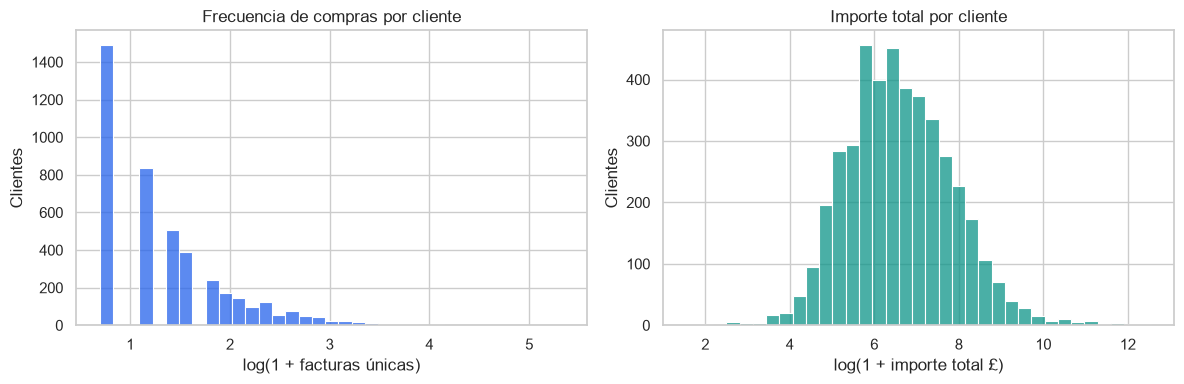

In [ ]:
exploracion_clientes = (
    ventas_clientes.groupby("CustomerID")
    .agg(
        FacturasUnicas=("InvoiceNo", "nunique"),
        ImporteTotal=("ImporteLinea", "sum"),
        ProductosDistintos=("StockCode", "nunique"),
        PrimeraCompra=("InvoiceDate", "min"),
        UltimaCompra=("InvoiceDate", "max"),
    )
)
print("Clientes evaluables:", f"{len(exploracion_clientes):,}")
display(exploracion_clientes.head())
display(exploracion_clientes[["FacturasUnicas", "ImporteTotal", "ProductosDistintos"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(exploracion_clientes["FacturasUnicas"]), bins=35, ax=axes[0], color="#2563EB")
axes[0].set(title="Frecuencia de compras por cliente", xlabel="log(1 + facturas únicas)", ylabel="Clientes")
sns.histplot(np.log1p(exploracion_clientes["ImporteTotal"]), bins=35, ax=axes[1], color="#0D9488")
axes[1].set(title="Importe total por cliente", xlabel="log(1 + importe total £)", ylabel="Clientes")
plt.tight_layout()
plt.show()

### 3.11. Resumen reproducible de hallazgos

In [ ]:
porcentaje = lambda cantidad, total: 100 * cantidad / total if total else 0.0

print("=== INDICADORES DE CONCLUSIONES DEL EDA ===")
print(f"Tamaño: {len(df):,} filas y {df.shape[1]} columnas")
print(f"Periodo observado: {df['InvoiceDate'].min()} — {df['InvoiceDate'].max()}")
print(f"CustomerID ausente: {df['CustomerID'].isna().sum():,} "
      f"({porcentaje(df['CustomerID'].isna().sum(), len(df)):.2f}%)")
print(f"Duplicados exactos: {df.duplicated().sum():,} "
      f"({porcentaje(df.duplicated().sum(), len(df)):.2f}%)")
print(f"Líneas de facturas marcadas C: {es_cancelacion.sum():,} "
      f"({porcentaje(es_cancelacion.sum(), len(df)):.2f}%)")
print(f"Líneas de compras positivas: {len(ventas_validas):,} "
      f"({porcentaje(len(ventas_validas), len(df)):.2f}%)")
print(f"Clientes identificables en las compras positivas: {len(exploracion_clientes):,}")
print(f"Mediana de facturas por cliente: {exploracion_clientes['FacturasUnicas'].median():.1f}")
print(f"Mediana de importe por cliente: £{exploracion_clientes['ImporteTotal'].median():,.2f}")
if len(paises):
    print(f"País con más clientes identificados: {paises.index[0]}")

=== INDICADORES DE CONCLUSIONES DEL EDA ===
Tamaño: 541,909 filas y 8 columnas
Periodo observado: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
CustomerID ausente: 135,080 (24.93%)
Duplicados exactos: 5,268 (0.97%)
Líneas de facturas marcadas C: 9,288 (1.71%)
Líneas de compras positivas: 530,104 (97.82%)
Clientes identificables en las compras positivas: 4,338
Mediana de facturas por cliente: 2.0
Mediana de importe por cliente: £674.49
País con más clientes identificados: United Kingdom


### 4. Conclusiones del análisis exploratorio de datos

El análisis exploratorio del dataset *Online Retail* permitió identificar características relevantes para el desarrollo del modelo de segmentación. Se evidenció que el 24,93 % de los registros carece de identificador de cliente, mientras que el 0,97 % corresponde a duplicados exactos. Asimismo, se encontraron cancelaciones, precios no positivos y valores extremos que requieren un tratamiento adecuado durante el preprocesamiento.

Las variables numéricas presentan distribuciones asimétricas, con predominio de transacciones de bajo importe y algunas operaciones de magnitud considerable. Esto justifica evaluar técnicas de transformación y escalamiento para reducir la influencia de valores extremos en los algoritmos de clustering.

Finalmente, se identificaron 4.338 clientes con compras positivas y una mediana de gasto acumulado de £674,49, lo que proporciona una base para construir características de comportamiento de compra. Estos hallazgos orientan la siguiente etapa del proyecto, enfocada en la limpieza de los datos y la generación de variables RFM para identificar patrones de consumo mediante aprendizaje no supervisado.

## 4. Preprocesamiento y construcción de características

In [17]:
import pandas as pd
import numpy as np

# Trabajar siempre desde el dataset original
df_tx = df.copy()

# Normalización de tipos
df_tx["CustomerID"] = pd.to_numeric(
    df_tx["CustomerID"], errors="coerce"
)

df_tx["InvoiceNo"] = (
    df_tx["InvoiceNo"].astype("string").str.strip()
)

df_tx["InvoiceDate"] = pd.to_datetime(
    df_tx["InvoiceDate"], errors="coerce"
)

df_tx["Quantity"] = pd.to_numeric(
    df_tx["Quantity"], errors="coerce"
)

df_tx["UnitPrice"] = pd.to_numeric(
    df_tx["UnitPrice"], errors="coerce"
)

# Conservar transacciones identificables con importe válido
condiciones = (
    df_tx["CustomerID"].notna()
    & df_tx["InvoiceNo"].notna()
    & df_tx["InvoiceDate"].notna()
    & (df_tx["UnitPrice"] > 0)
    & (df_tx["Quantity"] != 0)
    & df_tx["Quantity"].notna()
)

df_tx = df_tx.loc[condiciones].copy()

# Calcular importes positivos y negativos
df_tx["Importe"] = (
    df_tx["Quantity"] * df_tx["UnitPrice"]
)

# Identificar cancelaciones
df_tx["EsCancelacion"] = (
    df_tx["InvoiceNo"]
    .str.upper()
    .str.startswith("C", na=False)
)

# Compras positivas para variables de actividad
df_compras = df_tx[
    (df_tx["Quantity"] > 0)
    & (~df_tx["EsCancelacion"])
].copy()

print("Transacciones utilizables:", len(df_tx))
print("Líneas de compras positivas:", len(df_compras))
print("Líneas de importe negativo:", (df_tx["Importe"] < 0).sum())
print("Clientes con compras:", df_compras["CustomerID"].nunique())

Transacciones utilizables: 406789
Líneas de compras positivas: 397884
Líneas de importe negativo: 8905
Clientes con compras: 4338


In [20]:
# Fecha de referencia
fecha_referencia = (
    df_tx["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Características basadas en compras positivas
rfm = df_compras.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    GrossMonetary=("Importe", "sum"),
    ProductDiversity=("StockCode", "nunique")
)

# Importe neto: compras menos devoluciones
neto = df_tx.groupby("CustomerID")["Importe"].sum()

rfm["Monetary"] = neto.round(2)

# Recencia respecto a última compra positiva
rfm["Recency"] = (
    fecha_referencia - rfm["LastPurchase"]
).dt.days

# Auditoría antes de excluir clientes
print("Clientes antes del filtro:", len(rfm))
print("Clientes con gasto neto <= 0:",
      (rfm["Monetary"] <= 0).sum())

print("\nCliente 12346:")
display(rfm.loc[[12346]])

# Conservar clientes con gasto neto positivo
rfm = rfm[rfm["Monetary"] > 0].copy()

# Ticket promedio neto por factura positiva
rfm["AvgTicket"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

rfm = rfm.reset_index()

# Ordenar columnas
rfm = rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "AvgTicket",
        "ProductDiversity"
    ]
]

print("\nDataset RFM corregido:")
print("Dimensiones:", rfm.shape)

display(rfm.head())
display(rfm.describe())

Clientes antes del filtro: 4338
Clientes con gasto neto <= 0: 21

Cliente 12346:


,LastPurchase,Frequency,GrossMonetary,ProductDiversity,Monetary,Recency
CustomerID,,,,,,
"12,346.00",2011-01-18 10:01:00,1,"77,183.60",1,0.00,326



Dataset RFM corregido:
Dimensiones: (4317, 6)


,CustomerID,Recency,Frequency,Monetary,AvgTicket,ProductDiversity
0,"12,347.00",2,7,"4,310.00",615.71,103
1,"12,348.00",75,4,"1,797.24",449.31,22
2,"12,349.00",19,1,"1,757.55","1,757.55",73
3,"12,350.00",310,1,334.40,334.40,17
4,"12,352.00",36,8,"1,545.41",193.18,59


,CustomerID,Recency,Frequency,Monetary,AvgTicket,ProductDiversity
count,"4,317.00","4,317.00","4,317.00","4,317.00","4,317.00","4,317.00"
mean,"15,300.12",92.25,4.29,"1,925.71",367.96,61.74
std,"1,720.24",99.84,7.71,"8,267.65",399.87,85.49
min,"12,347.00",1.00,1.00,2.90,1.45,1.00
25%,"13,815.00",18.00,1.00,302.70,175.20,16.00
50%,"15,299.00",51.00,2.00,658.26,284.55,36.00
75%,"16,778.00",141.00,5.00,"1,627.13",423.33,78.00
max,"18,287.00",374.00,209.00,"279,489.02","7,178.63","1,787.00"


In [19]:
# Comparar importes netos conservando y eliminando duplicados
neto_original = (
    df_tx.groupby("CustomerID")["Importe"].sum()
)

neto_sin_duplicados = (
    df_tx.drop_duplicates()
    .groupby("CustomerID")["Importe"]
    .sum()
)

comparacion = pd.DataFrame({
    "ConDuplicados": neto_original,
    "SinDuplicados": neto_sin_duplicados
})

comparacion["Diferencia"] = (
    comparacion["ConDuplicados"]
    - comparacion["SinDuplicados"]
)

print(
    "Clientes con diferencia monetaria:",
    (comparacion["Diferencia"].abs() > 0.001).sum()
)

print(
    "Diferencia neta total:",
    round(comparacion["Diferencia"].sum(), 2)
)

print("\nMayores diferencias absolutas:")

display(
    comparacion.reindex(
        comparacion["Diferencia"].abs()
        .sort_values(ascending=False)
        .index
    ).head(10)
)

Clientes con diferencia monetaria: 958
Diferencia neta total: 21546.39

Mayores diferencias absolutas:


,ConDuplicados,SinDuplicados,Diferencia
CustomerID,,,
"16,029.00","50,992.61","53,168.69","-2,176.08"
"12,748.00","29,072.10","28,405.56",666.54
"17,841.00","40,340.78","39,869.05",471.73
"14,607.00","11,341.10","10,981.10",360.00
"16,762.00","1,501.38","1,207.24",294.14
"14,769.00","10,641.60","10,383.83",257.77
"14,102.00","1,314.73","1,060.33",254.40
"13,316.00","5,815.49","5,570.69",244.80
"15,856.00","16,173.67","15,929.74",243.93


### Resultados del preprocesamiento y tratamiento de transacciones

La reconstrucción del conjunto de características permitió obtener inicialmente 4.322 clientes con gasto neto positivo, tras excluir 16 clientes cuyo saldo monetario era nulo o negativo. Esta modificación corrigió situaciones en las que las compras posteriormente devueltas producían una sobreestimación del valor económico del cliente.

El análisis de sensibilidad de los duplicados identificó diferencias monetarias en 958 clientes y una variación neta agregada de £21.546,39. Sin embargo, dado que no es posible determinar con certeza si todas las coincidencias corresponden a errores de registro, se decidió conservarlas inicialmente y evaluar posteriormente su influencia sobre la estabilidad de la segmentación.

Las características obtenidas presentan distribuciones heterogéneas y valores extremos, especialmente en las variables monetarias y de frecuencia. En consecuencia, se considera necesario evaluar transformaciones estadísticas, escalamiento y selección de características antes de aplicar los algoritmos de clustering.

## 5. Análisis de características y selección de variables

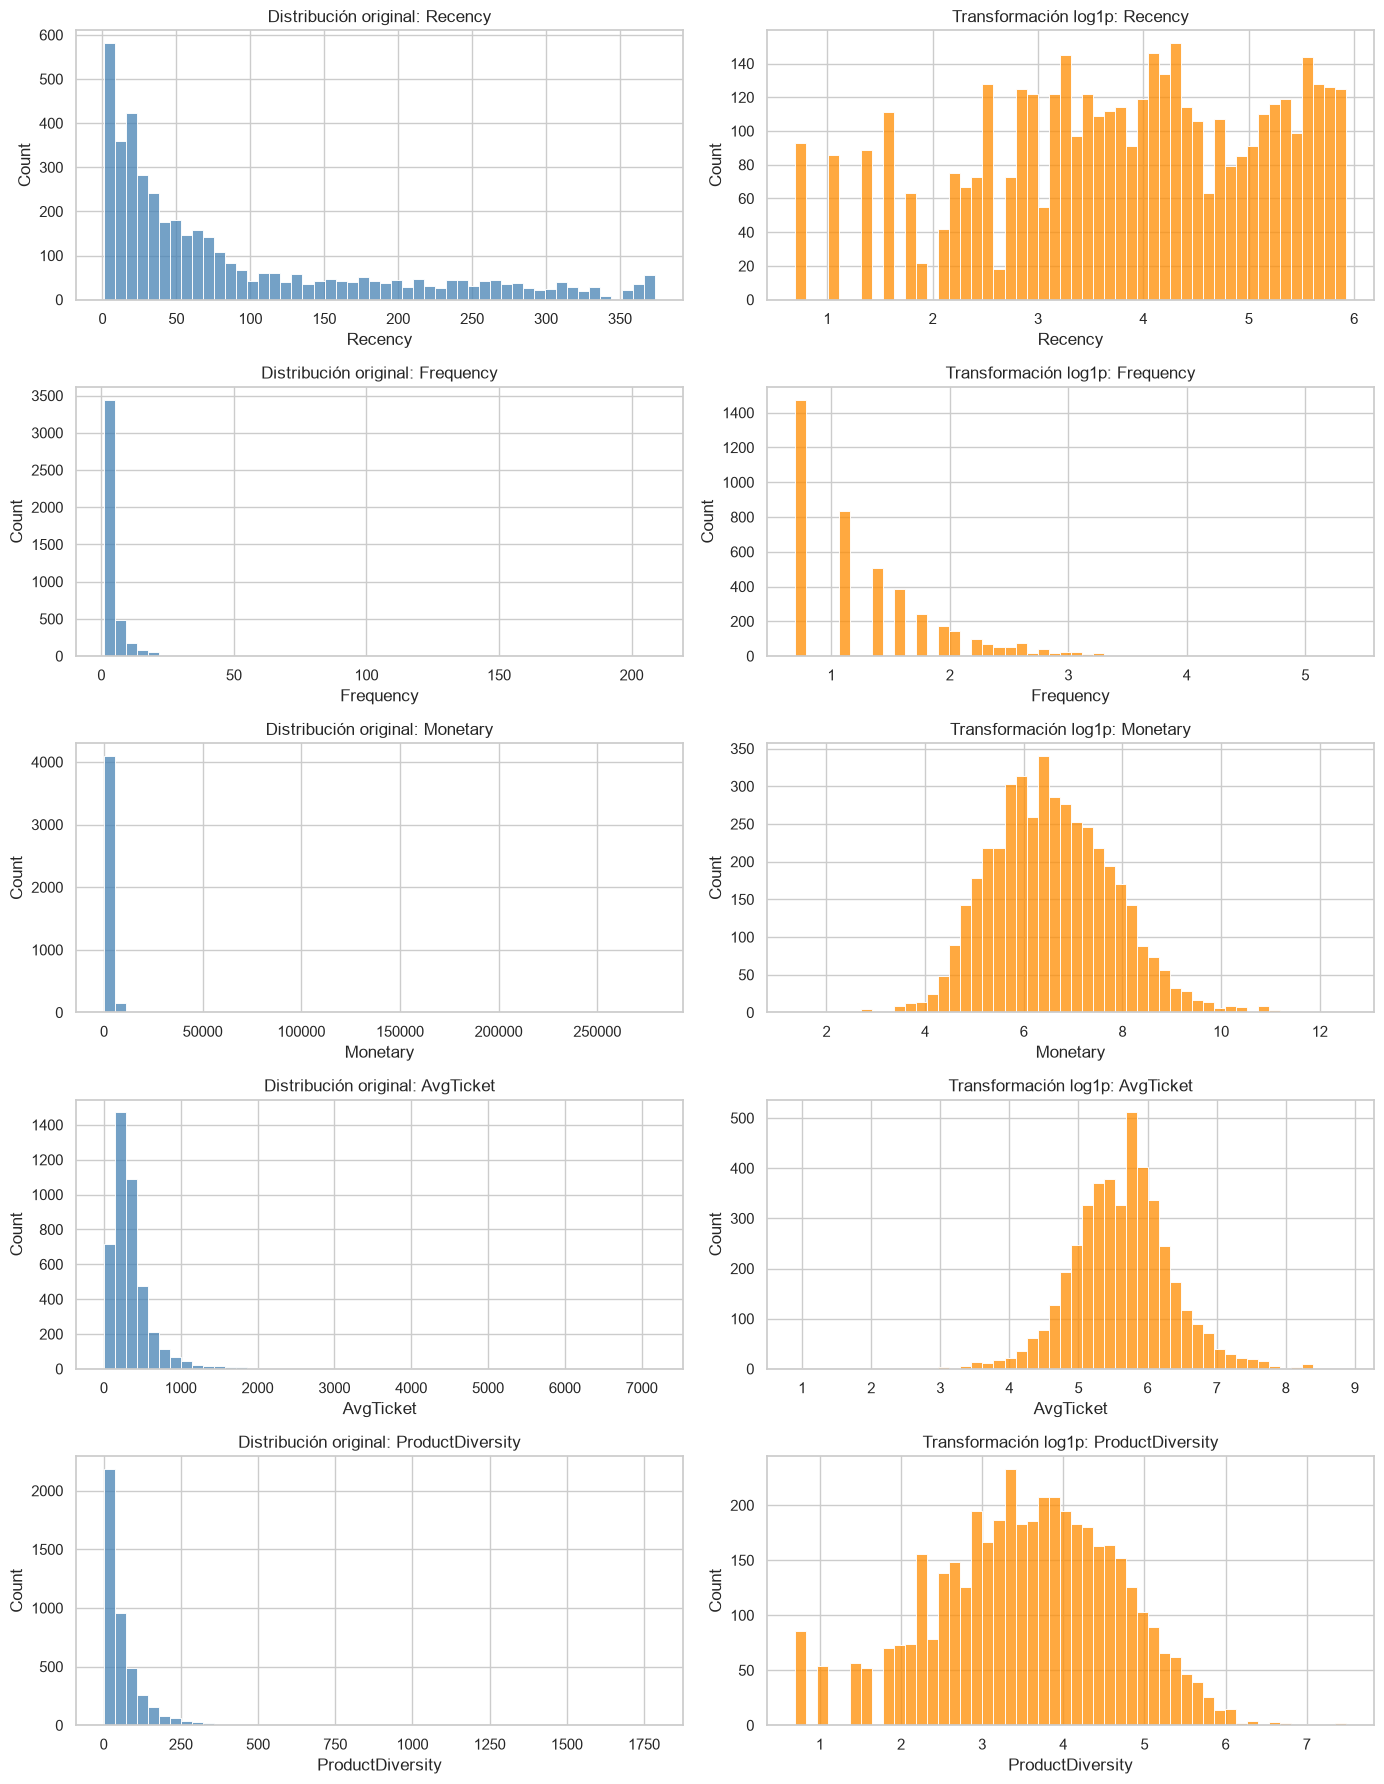

,Original,Log1p
Recency,1.25,-0.38
Frequency,12.05,1.20
Monetary,21.59,0.37
AvgTicket,6.50,-0.00
ProductDiversity,6.92,-0.24


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgTicket",
    "ProductDiversity"
]

fig, axes = plt.subplots(
    len(variables), 2,
    figsize=(14, 18)
)

for i, variable in enumerate(variables):

    # Distribución original
    sns.histplot(
        rfm[variable],
        bins=50,
        ax=axes[i, 0],
        color="steelblue"
    )

    axes[i, 0].set_title(
        f"Distribución original: {variable}"
    )

    # Distribución transformada
    sns.histplot(
        np.log1p(rfm[variable]),
        bins=50,
        ax=axes[i, 1],
        color="darkorange"
    )

    axes[i, 1].set_title(
        f"Transformación log1p: {variable}"
    )

plt.tight_layout()
plt.show()

# Medir asimetría
asimetria = pd.DataFrame({
    "Original": rfm[variables].skew(),
    "Log1p": np.log1p(rfm[variables]).skew()
})

display(asimetria.round(3))

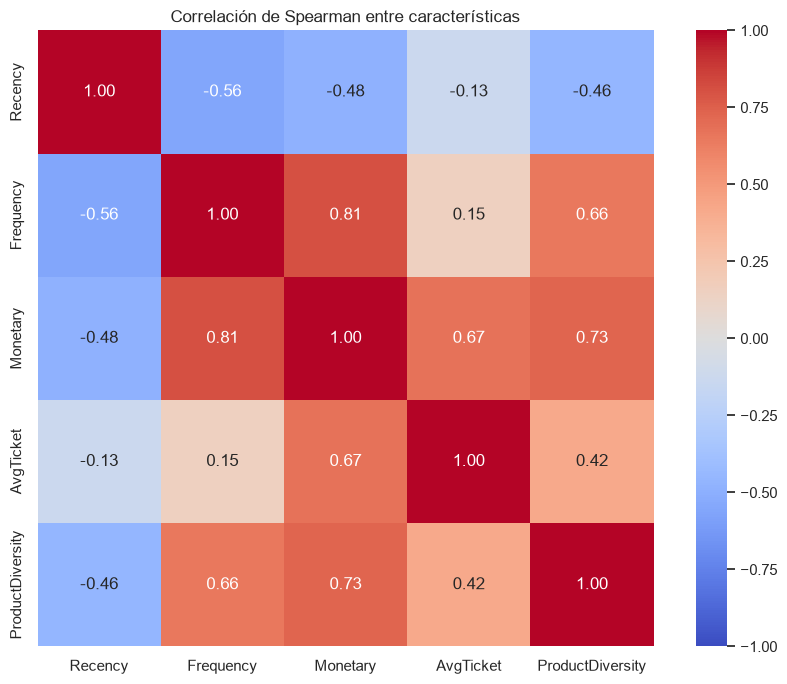

Pares con correlación absoluta >= 0.85:


,Variable 1,Variable 2,Correlacion,AbsCorrelacion


In [22]:
# Correlación de Spearman
corr = rfm[variables].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlación de Spearman entre características"
)

plt.tight_layout()
plt.show()

# Identificar pares altamente correlacionados
umbral = 0.85

mascara = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)

pares = (
    corr.where(mascara)
    .stack()
    .reset_index()
)

pares.columns = [
    "Variable 1",
    "Variable 2",
    "Correlacion"
]

pares["AbsCorrelacion"] = (
    pares["Correlacion"].abs()
)

pares_altos = pares[
    pares["AbsCorrelacion"] >= umbral
].sort_values(
    "AbsCorrelacion",
    ascending=False
)

print("Pares con correlación absoluta >= 0.85:")
display(pares_altos)

### Conclusiones del análisis de características

El análisis de las variables RFM evidenció distribuciones marcadamente asimétricas, especialmente en las características monetarias y de frecuencia. La transformación logarítmica log1p redujo considerablemente dicha asimetría, destacándose la variable Monetary, cuyo coeficiente pasó de 21,59 a 0,37.

El análisis de correlación de Spearman identificó una asociación positiva elevada entre Frequency y Monetary (0,81), así como una relación negativa moderada entre Recency y Frequency (−0,56). Estos resultados indican que existen características parcialmente redundantes que podrían influir en la ponderación implícita de las distancias utilizadas por los algoritmos.

Por tanto, se decidió incorporar transformaciones logarítmicas, estandarización y selección de características por correlación dentro del pipeline de aprendizaje automático. Se evaluarán distintos umbrales de selección mediante validación cruzada, con el objetivo de determinar si la reducción de variables contribuye a obtener segmentos de clientes más diferenciados y estables.

## 6. Pipeline de preprocesamiento y selección de características

In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Copia del dataset de clientes
rfm_modelo = rfm.copy()

# Redondear importes monetarios para evitar residuos numéricos
rfm_modelo["Monetary"] = (
    rfm_modelo["Monetary"].round(2)
)

# Excluir importes netos no positivos
rfm_modelo = rfm_modelo[
    rfm_modelo["Monetary"] > 0
].copy()

# Actualizar ticket promedio
rfm_modelo["AvgTicket"] = (
    rfm_modelo["Monetary"]
    / rfm_modelo["Frequency"]
)

# Características candidatas
# Monetary precede a Frequency como prioridad de conservación
features = [
    "Recency",
    "Monetary",
    "Frequency",
    "ProductDiversity"
]

X = rfm_modelo[features].copy()

assert X.notna().all().all()
assert np.isfinite(X.to_numpy()).all()
assert (X >= 0).all().all()

# Reservar un conjunto independiente
X_desarrollo, X_reserva = train_test_split(
    X,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Dataset completo:", X.shape)
print("Conjunto de desarrollo:", X_desarrollo.shape)
print("Conjunto de reserva:", X_reserva.shape)

display(X_desarrollo.head())

Dataset completo: (4317, 4)
Conjunto de desarrollo: (3453, 4)
Conjunto de reserva: (864, 4)


,Recency,Monetary,Frequency,ProductDiversity
279,70,869.67,2,32
3435,131,496.38,1,13
3523,8,"3,286.91",6,42
1864,2,"1,025.44",2,66
2028,60,"1,419.54",4,74


In [24]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class CorrelationFilter(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.85):
        self.threshold = threshold

    def fit(self, X, y=None):

        X = np.asarray(X, dtype=float)

        corr = (
            pd.DataFrame(X)
            .corr(method="spearman")
            .abs()
            .fillna(0)
        )

        seleccionadas = []

        for j in range(X.shape[1]):

            redundante = any(
                corr.iloc[j, k] >= self.threshold
                for k in seleccionadas
            )

            if not redundante:
                seleccionadas.append(j)

        self.selected_indices_ = np.array(
            seleccionadas, dtype=int
        )

        self.n_features_in_ = X.shape[1]

        return self

    def transform(self, X):

        check_is_fitted(self, "selected_indices_")

        X = np.asarray(X, dtype=float)

        return X[:, self.selected_indices_]

    def get_feature_names_out(self, input_features=None):

        check_is_fitted(self, "selected_indices_")

        if input_features is None:
            input_features = [
                f"x{i}" for i in range(self.n_features_in_)
            ]

        return np.asarray(input_features)[
            self.selected_indices_
        ]

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler
)

# Comparar dos umbrales de selección
for umbral in [0.80, 0.85]:

    pipeline_preprocesamiento = Pipeline([
        (
            "log",
            FunctionTransformer(np.log1p)
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "selection",
            CorrelationFilter(threshold=umbral)
        )
    ])

    # Ajuste exploratorio SOLO sobre desarrollo
    X_transformado = (
        pipeline_preprocesamiento
        .fit_transform(X_desarrollo)
    )

    selector = (
        pipeline_preprocesamiento
        .named_steps["selection"]
    )

    variables_seleccionadas = (
        selector.get_feature_names_out(features)
    )

    print(f"\n--- Umbral: {umbral} ---")
    print(
        "Dimensiones transformadas:",
        X_transformado.shape
    )
    print(
        "Variables seleccionadas:",
        list(variables_seleccionadas)
    )


--- Umbral: 0.8 ---
Dimensiones transformadas: (3453, 3)
Variables seleccionadas: [np.str_('Recency'), np.str_('Monetary'), np.str_('ProductDiversity')]

--- Umbral: 0.85 ---
Dimensiones transformadas: (3453, 4)
Variables seleccionadas: [np.str_('Recency'), np.str_('Monetary'), np.str_('Frequency'), np.str_('ProductDiversity')]


## 7. Implementación y evaluación inicial de modelos de clustering

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split(
    X_desarrollo,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Clientes de entrenamiento:", X_train.shape[0])
print("Clientes de validación:", X_val.shape[0])
print("Clientes de reserva:", X_reserva.shape[0])

Clientes de entrenamiento: 2762
Clientes de validación: 691
Clientes de reserva: 864


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import numpy as np
import pandas as pd


def construir_pipeline(algoritmo, k, umbral=0.85):

    if algoritmo == "K-Means":

        modelo = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        )

    elif algoritmo == "GMM":

        modelo = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=3,
            reg_covar=1e-4,
            max_iter=300,
            random_state=42
        )

    else:
        raise ValueError("Algoritmo no reconocido")

    pipeline = Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scaler", StandardScaler()),
        ("selection", CorrelationFilter(threshold=umbral)),
        ("model", modelo)
    ])

    return pipeline

In [28]:
resultados = []

for algoritmo in ["K-Means", "GMM"]:

    for k in range(2, 9):

        pipeline = construir_pipeline(
            algoritmo=algoritmo,
            k=k,
            umbral=0.85
        )

        # Ajustar únicamente con entrenamiento
        pipeline.fit(X_train)

        # Asignar clusters a validación
        etiquetas = pipeline.predict(X_val)

        # Aplicar preprocesamiento aprendido
        X_val_transformado = pipeline[:-1].transform(X_val)

        # Número de clusters efectivamente observados
        clusters, conteos = np.unique(
            etiquetas,
            return_counts=True
        )

        n_clusters = len(clusters)
        grupo_minimo = int(conteos.min())

        # Algunas configuraciones pueden producir
        # un único cluster en validación
        if 2 <= n_clusters < len(etiquetas):

            silhouette = silhouette_score(
                X_val_transformado,
                etiquetas
            )

            davies = davies_bouldin_score(
                X_val_transformado,
                etiquetas
            )

            calinski = calinski_harabasz_score(
                X_val_transformado,
                etiquetas
            )

        else:

            silhouette = np.nan
            davies = np.nan
            calinski = np.nan

        resultados.append({
            "Algoritmo": algoritmo,
            "k": k,
            "ClustersObservados": n_clusters,
            "GrupoMinimo": grupo_minimo,
            "Silhouette": silhouette,
            "DaviesBouldin": davies,
            "CalinskiHarabasz": calinski
        })

resultados = pd.DataFrame(resultados)

display(resultados.round(3))

,Algoritmo,k,ClustersObservados,GrupoMinimo,Silhouette,DaviesBouldin,CalinskiHarabasz
0,K-Means,2,2,274,0.40,0.96,617.95
1,K-Means,3,3,135,0.30,1.12,505.63
2,K-Means,4,4,127,0.31,1.16,441.53
3,K-Means,5,5,79,0.25,1.17,402.48
4,K-Means,6,6,62,0.23,1.25,360.41
5,K-Means,7,7,45,0.23,1.16,339.44
6,K-Means,8,8,43,0.22,1.24,316.01
7,GMM,2,2,238,0.26,1.13,335.02
8,GMM,3,3,113,0.21,1.60,257.73
9,GMM,4,4,93,0.12,1.98,217.02


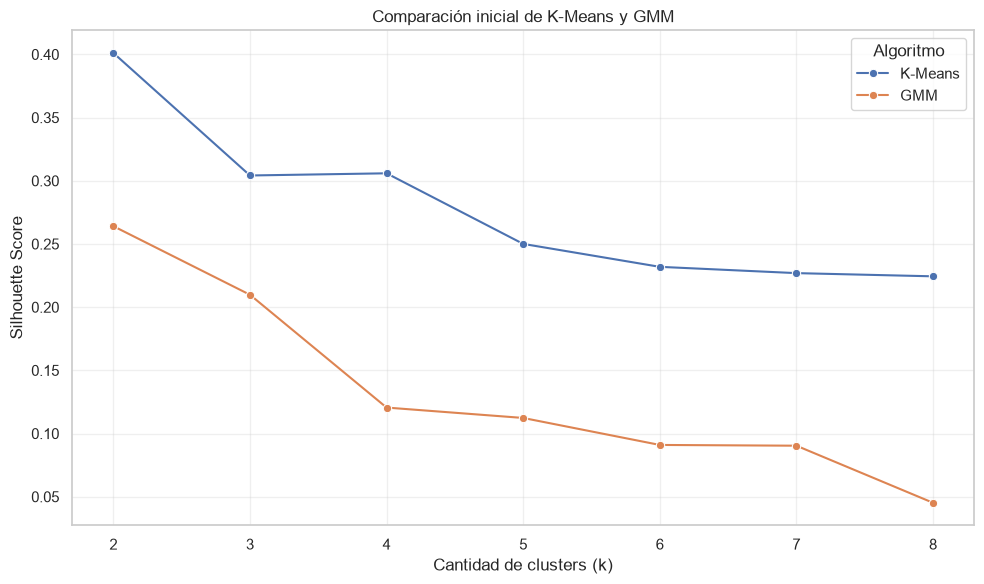

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=resultados,
    x="k",
    y="Silhouette",
    hue="Algoritmo",
    marker="o"
)

plt.title(
    "Comparación inicial de K-Means y GMM"
)

plt.xlabel("Cantidad de clusters (k)")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Resultados de la evaluación inicial de los modelos

La evaluación preliminar de los algoritmos K-Means y Gaussian Mixture Models evidenció diferencias en la calidad de los agrupamientos obtenidos. K-Means presentó un rendimiento superior en las configuraciones evaluadas, alcanzando un Silhouette Score de 0,40 con dos clusters, frente a 0,26 obtenido por GMM.

Las métricas Davies-Bouldin y Calinski-Harabasz también favorecieron a K-Means. Adicionalmente, se observó una tendencia general a la disminución del desempeño conforme aumentó el número de grupos, especialmente en GMM, donde algunas configuraciones generaron clusters de tamaño reducido.

Aunque estos resultados sugieren que K-Means podría representar mejor la estructura de los datos, la evaluación corresponde a una única partición de entrenamiento y validación. Por ello, se realizará una optimización de hiperparámetros utilizando validación cruzada repetida, con el objetivo de analizar la consistencia de los resultados y seleccionar configuraciones más robustas.

## 8. Optimización de hiperparámetros mediante validación cruzada repetida

In [30]:
from itertools import product
from sklearn.model_selection import RepeatedKFold

# Validación cruzada repetida
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=42
)

particiones = list(cv.split(X_desarrollo))

configuraciones = []

# Configuraciones de K-Means
for k, umbral, n_init in product(
    range(2, 7),
    [0.80, 0.85],
    [10, 20]
):
    configuraciones.append({
        "Algoritmo": "K-Means",
        "k": k,
        "Umbral": umbral,
        "n_init": n_init,
        "covariance_type": None,
        "reg_covar": None
    })

# Configuraciones de GMM
for k, umbral, covariance, reg_covar in product(
    range(2, 7),
    [0.80, 0.85],
    ["full", "diag"],
    [1e-4, 1e-3]
):
    configuraciones.append({
        "Algoritmo": "GMM",
        "k": k,
        "Umbral": umbral,
        "n_init": 2,
        "covariance_type": covariance,
        "reg_covar": reg_covar
    })

print("Configuraciones:", len(configuraciones))
print("Folds por configuración:", len(particiones))
print(
    "Total de entrenamientos:",
    len(configuraciones) * len(particiones)
)

Configuraciones: 60
Folds por configuración: 10
Total de entrenamientos: 600


In [31]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler
)

def construir_pipeline_cv(config):

    if config["Algoritmo"] == "K-Means":

        modelo = KMeans(
            n_clusters=config["k"],
            n_init=config["n_init"],
            init="k-means++",
            random_state=42
        )

    else:

        modelo = GaussianMixture(
            n_components=config["k"],
            covariance_type=config["covariance_type"],
            reg_covar=config["reg_covar"],
            n_init=config["n_init"],
            max_iter=300,
            random_state=42
        )

    return Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scaler", StandardScaler()),
        (
            "selection",
            CorrelationFilter(
                threshold=config["Umbral"]
            )
        ),
        ("model", modelo)
    ])

In [32]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import silhouette_score

resultados_cv = []

inicio = time.perf_counter()

for idx, config in enumerate(configuraciones):

    for fold, (train_idx, val_idx) in enumerate(particiones):

        X_tr = X_desarrollo.iloc[train_idx]
        X_vl = X_desarrollo.iloc[val_idx]

        pipeline = construir_pipeline_cv(config)

        # Entrenar únicamente con el fold de entrenamiento
        pipeline.fit(X_tr)

        # Predecir clusters en validación
        etiquetas = pipeline.predict(X_vl)

        # Transformar validación con parámetros aprendidos
        X_vl_transformado = (
            pipeline[:-1].transform(X_vl)
        )

        grupos, conteos = np.unique(
            etiquetas,
            return_counts=True
        )

        proporcion_minima = (
            conteos.min() / len(etiquetas)
        )

        valido = (
            len(grupos) == config["k"]
            and proporcion_minima >= 0.01
        )

        if valido:

            score = silhouette_score(
                X_vl_transformado,
                etiquetas
            )

        else:
            score = np.nan

        resultados_cv.append({
            "ConfigID": idx,
            "Fold": fold,
            "Silhouette": score,
            "Valido": valido,
            "ProporcionMinima": proporcion_minima
        })

    if (idx + 1) % 10 == 0:

        transcurrido = time.perf_counter() - inicio

        print(
            f"Configuraciones completadas: "
            f"{idx + 1}/{len(configuraciones)} | "
            f"{transcurrido:.1f} segundos"
        )

resultados_cv = pd.DataFrame(resultados_cv)

print("\nOptimización completada.")
print(
    "Tiempo total:",
    round(time.perf_counter() - inicio, 2),
    "segundos"
)

Configuraciones completadas: 10/60 | 5.8 segundos
Configuraciones completadas: 20/60 | 13.9 segundos
Configuraciones completadas: 30/60 | 22.1 segundos
Configuraciones completadas: 40/60 | 31.1 segundos
Configuraciones completadas: 50/60 | 43.6 segundos
Configuraciones completadas: 60/60 | 55.5 segundos

Optimización completada.
Tiempo total: 55.53 segundos


In [33]:
# Consolidar las puntuaciones por configuración
resumen_cv = (
    resultados_cv
    .groupby("ConfigID")
    .agg(
        SilhouetteMedio=("Silhouette", "mean"),
        SilhouetteStd=("Silhouette", "std"),
        FoldsValidos=("Valido", "sum"),
        MinProporcion=("ProporcionMinima", "min")
    )
    .reset_index()
)

# Incorporar hiperparámetros
parametros_df = pd.DataFrame(configuraciones)
parametros_df["ConfigID"] = parametros_df.index

resumen_cv = parametros_df.merge(
    resumen_cv,
    on="ConfigID"
)

# Elegibles: válidas en todos los folds
resumen_cv["Elegible"] = (
    resumen_cv["FoldsValidos"] == len(particiones)
)

resultados_elegibles = (
    resumen_cv[resumen_cv["Elegible"]]
    .sort_values(
        "SilhouetteMedio",
        ascending=False
    )
)

print("Configuraciones válidas:", len(resultados_elegibles))

print("\nMejores configuraciones de K-Means:")
display(
    resultados_elegibles[
        resultados_elegibles["Algoritmo"] == "K-Means"
    ].head(5).round(4)
)

print("\nMejores configuraciones de GMM:")
display(
    resultados_elegibles[
        resultados_elegibles["Algoritmo"] == "GMM"
    ].head(5).round(4)
)

Configuraciones válidas: 60

Mejores configuraciones de K-Means:


,Algoritmo,k,Umbral,n_init,covariance_type,reg_covar,ConfigID,SilhouetteMedio,SilhouetteStd,FoldsValidos,MinProporcion,Elegible
3,K-Means,2,0.85,20,NaN,NaN,3,0.40,0.01,10,0.38,True
2,K-Means,2,0.85,10,NaN,NaN,2,0.40,0.01,10,0.38,True
1,K-Means,2,0.80,20,NaN,NaN,1,0.38,0.01,10,0.42,True
0,K-Means,2,0.80,10,NaN,NaN,0,0.38,0.01,10,0.42,True
6,K-Means,3,0.85,10,NaN,NaN,6,0.30,0.01,10,0.18,True



Mejores configuraciones de GMM:


,Algoritmo,k,Umbral,n_init,covariance_type,reg_covar,ConfigID,SilhouetteMedio,SilhouetteStd,FoldsValidos,MinProporcion,Elegible
27,GMM,2,0.85,2,diag,0.00,27,0.39,0.01,10,0.40,True
26,GMM,2,0.85,2,diag,0.00,26,0.39,0.01,10,0.40,True
23,GMM,2,0.80,2,diag,0.00,23,0.38,0.01,10,0.42,True
22,GMM,2,0.80,2,diag,0.00,22,0.38,0.01,10,0.42,True
25,GMM,2,0.85,2,full,0.00,25,0.29,0.04,10,0.32,True


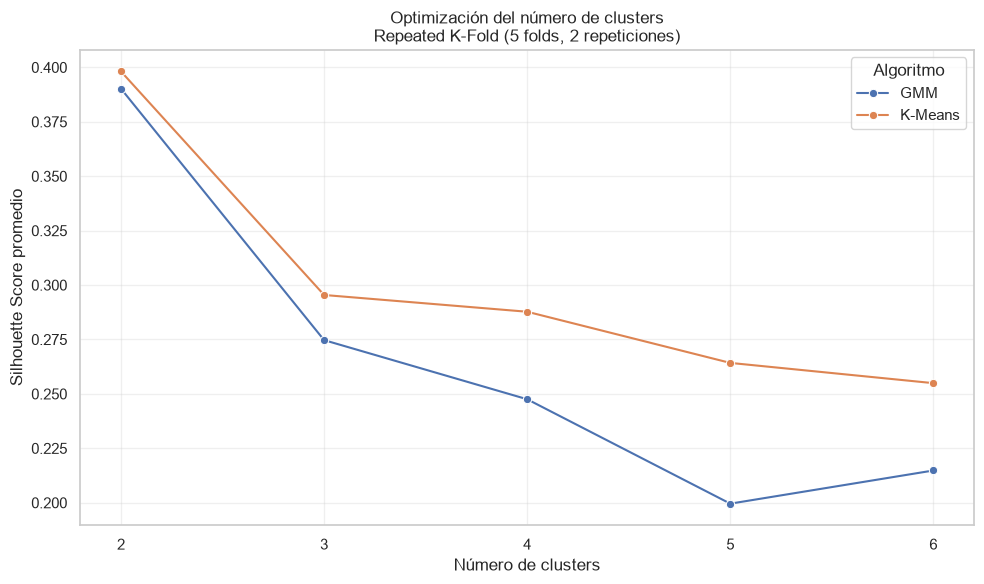

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

grafico_cv = (
    resultados_elegibles
    .groupby(["Algoritmo", "k"], as_index=False)
    .agg(
        SilhouetteMedio=("SilhouetteMedio", "max")
    )
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=grafico_cv,
    x="k",
    y="SilhouetteMedio",
    hue="Algoritmo",
    marker="o"
)

plt.title(
    "Optimización del número de clusters\n"
    "Repeated K-Fold (5 folds, 2 repeticiones)"
)

plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score promedio")
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusiones de la optimización de hiperparámetros

La optimización mediante Repeated K-Fold Cross-Validation, utilizando cinco particiones y dos repeticiones, permitió evaluar 60 configuraciones de los algoritmos K-Means y Gaussian Mixture Models, con un total de 600 entrenamientos.

Los mejores resultados se obtuvieron con dos clusters en ambos algoritmos. K-Means alcanzó un Silhouette Score promedio aproximado de 0,40, mientras que GMM obtuvo 0,39 utilizando una matriz de covarianza diagonal. Ambas configuraciones presentaron desviaciones estándar cercanas a 0,01, lo que sugiere una variabilidad reducida de las puntuaciones durante la validación.

La optimización mejoró especialmente el desempeño de GMM respecto a los experimentos preliminares, reduciendo considerablemente la diferencia con K-Means.

Aunque K-Means obtuvo la mayor puntuación promedio, la diferencia observada es pequeña. Por tanto, no se considera suficiente para establecer una superioridad concluyente y se procederá a realizar una comparación estadística de ambos algoritmos mediante una evaluación separada de la optimización.

Estos resultados también sugieren que una segmentación de dos grupos podría representar la estructura predominante de los datos, aunque será necesario analizar posteriormente su interpretación comercial.

## 9. Comparación estadística de algoritmos

In [35]:
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.metrics import silhouette_score

# Validación externa: 5 folds, 2 repeticiones
cv_externo = RepeatedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=2026
)

particiones_externas = list(
    cv_externo.split(X_desarrollo)
)

# Separar configuraciones por algoritmo
configs_por_algoritmo = {
    algoritmo: [
        c for c in configuraciones
        if c["Algoritmo"] == algoritmo
    ]
    for algoritmo in ["K-Means", "GMM"]
}

print("Particiones externas:", len(particiones_externas))
print(
    "Configuraciones K-Means:",
    len(configs_por_algoritmo["K-Means"])
)
print(
    "Configuraciones GMM:",
    len(configs_por_algoritmo["GMM"])
)

Particiones externas: 10
Configuraciones K-Means: 20
Configuraciones GMM: 40


In [36]:
def evaluar_configuracion(config, X_tr, X_vl):

    pipeline = construir_pipeline_cv(config)

    pipeline.fit(X_tr)

    etiquetas = pipeline.predict(X_vl)

    grupos, conteos = np.unique(
        etiquetas,
        return_counts=True
    )

    # Exigir todos los clusters y un tamaño mínimo
    valido = (
        len(grupos) == config["k"]
        and conteos.min() / len(etiquetas) >= 0.01
    )

    if not valido:
        return np.nan

    X_transformado = pipeline[:-1].transform(X_vl)

    return float(
        silhouette_score(X_transformado, etiquetas)
    )

In [37]:
resultados_nested = []
mejores_configs_nested = []

inicio = time.perf_counter()

for fold_externo, (idx_tr, idx_val) in enumerate(
    particiones_externas, start=1
):

    X_outer_train = X_desarrollo.iloc[idx_tr]
    X_outer_val = X_desarrollo.iloc[idx_val]

    # Particiones internas creadas sobre entrenamiento externo
    cv_interno = KFold(
        n_splits=3,
        shuffle=True,
        random_state=100 + fold_externo
    )

    particiones_internas = list(
        cv_interno.split(X_outer_train)
    )

    for algoritmo in ["K-Means", "GMM"]:

        mejor_score = -np.inf
        mejor_config = None

        # Optimización interna
        for config in configs_por_algoritmo[algoritmo]:

            scores_internos = []

            for idx_inner_tr, idx_inner_val in particiones_internas:

                X_inner_tr = X_outer_train.iloc[idx_inner_tr]
                X_inner_val = X_outer_train.iloc[idx_inner_val]

                score = evaluar_configuracion(
                    config,
                    X_inner_tr,
                    X_inner_val
                )

                scores_internos.append(score)

            scores_internos = np.asarray(
                scores_internos,
                dtype=float
            )

            # Exigir validez en todas las particiones internas
            if not np.isfinite(scores_internos).all():
                continue

            score_medio = scores_internos.mean()

            if score_medio > mejor_score:
                mejor_score = score_medio
                mejor_config = config.copy()

        if mejor_config is None:
            raise RuntimeError(
                f"No hay configuración válida: "
                f"{algoritmo}, fold {fold_externo}"
            )

        # Evaluación externa: datos no usados para optimizar
        score_externo = evaluar_configuracion(
            mejor_config,
            X_outer_train,
            X_outer_val
        )

        resultados_nested.append({
            "Fold": fold_externo,
            "Algoritmo": algoritmo,
            "Silhouette": score_externo
        })

        mejores_configs_nested.append({
            "Fold": fold_externo,
            **mejor_config,
            "ScoreInterno": mejor_score,
            "ScoreExterno": score_externo
        })

    print(
        f"Fold externo {fold_externo}/10 completado | "
        f"{time.perf_counter()-inicio:.1f} segundos"
    )

resultados_nested = pd.DataFrame(resultados_nested)

mejores_configs_nested = pd.DataFrame(
    mejores_configs_nested
)

print("\nEvaluación anidada finalizada.")
print(
    "Tiempo total:",
    round(time.perf_counter()-inicio, 2),
    "segundos"
)

display(resultados_nested)

Fold externo 1/10 completado | 18.2 segundos
Fold externo 2/10 completado | 34.8 segundos
Fold externo 3/10 completado | 51.0 segundos
Fold externo 4/10 completado | 67.7 segundos
Fold externo 5/10 completado | 84.4 segundos
Fold externo 6/10 completado | 100.6 segundos
Fold externo 7/10 completado | 117.2 segundos
Fold externo 8/10 completado | 133.7 segundos
Fold externo 9/10 completado | 150.5 segundos
Fold externo 10/10 completado | 167.0 segundos

Evaluación anidada finalizada.
Tiempo total: 166.98 segundos


,Fold,Algoritmo,Silhouette
0,1,K-Means,0.40
1,1,GMM,0.39
2,2,K-Means,0.40
3,2,GMM,0.38
4,3,K-Means,0.41
5,3,GMM,0.41
6,4,K-Means,0.40
7,4,GMM,0.40
8,5,K-Means,0.38
9,5,GMM,0.38


In [38]:
from scipy.stats import wilcoxon

# Emparejar puntuaciones por fold externo
pares = resultados_nested.pivot(
    index="Fold",
    columns="Algoritmo",
    values="Silhouette"
)

print("Puntuaciones emparejadas:")
display(pares.round(4))

# Excluir pares inválidos, si existen
pares_validos = pares.dropna()

diferencias = (
    pares_validos["K-Means"]
    - pares_validos["GMM"]
)

print("\nResumen descriptivo:")

display(
    pares_validos.agg(["mean", "std", "median"]).round(4)
)

print(
    "Diferencia media:",
    round(diferencias.mean(), 4)
)

print(
    "Diferencia mediana:",
    round(diferencias.median(), 4)
)

print(
    "Folds favorables a K-Means:",
    int((diferencias > 0).sum())
)

print(
    "Folds favorables a GMM:",
    int((diferencias < 0).sum())
)

# Contraste exploratorio
if len(pares_validos) < 3:
    print("No hay suficientes pares para el contraste.")
elif np.all(diferencias == 0):
    print("Todas las diferencias son exactamente cero.")
else:
    estadistico, p_valor = wilcoxon(
        diferencias,
        alternative="two-sided",
        zero_method="wilcox",
        method="auto"
    )

    print("\n=== PRUEBA DE WILCOXON ===")
    print("Estadístico:", round(estadistico, 4))
    print("p-valor:", round(p_valor, 6))

    if p_valor < 0.05:
        print(
            "Resultado exploratorio: se rechaza H0 "
            "bajo los supuestos del contraste."
        )
    else:
        print(
            "Resultado exploratorio: no se rechaza H0."
        )

Puntuaciones emparejadas:


Algoritmo,GMM,K-Means
Fold,,
1,0.39,0.40
2,0.38,0.40
3,0.41,0.41
4,0.40,0.40
5,0.38,0.38
6,0.39,0.40
7,0.39,0.39
8,0.39,0.40
9,0.40,0.40



Resumen descriptivo:


Algoritmo,GMM,K-Means
mean,0.39,0.40
std,0.01,0.01
median,0.39,0.40


Diferencia media: 0.0076
Diferencia mediana: 0.0068
Folds favorables a K-Means: 10
Folds favorables a GMM: 0

=== PRUEBA DE WILCOXON ===
Estadístico: 0.0
p-valor: 0.001953
Resultado exploratorio: se rechaza H0 bajo los supuestos del contraste.


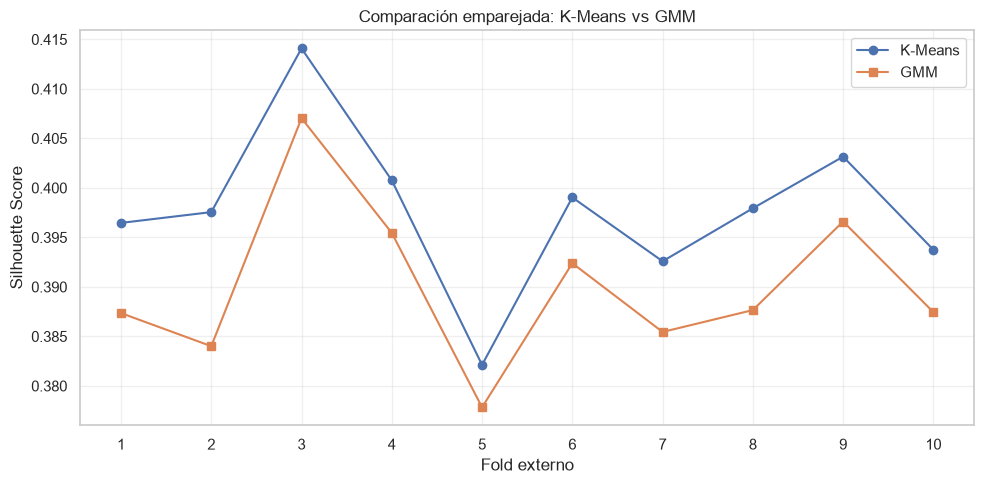

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    pares.index,
    pares["K-Means"],
    marker="o",
    label="K-Means"
)

plt.plot(
    pares.index,
    pares["GMM"],
    marker="s",
    label="GMM"
)

plt.xlabel("Fold externo")
plt.ylabel("Silhouette Score")
plt.title(
    "Comparación emparejada: K-Means vs GMM"
)

plt.xticks(pares.index)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones de la comparación estadística de algoritmos

La comparación de K-Means y Gaussian Mixture Models se realizó mediante validación cruzada anidada, utilizando cinco particiones externas y dos repeticiones. La selección de hiperparámetros se efectuó mediante validación interna, evitando utilizar directamente las puntuaciones de optimización para evaluar el rendimiento de los algoritmos.

Los resultados favorecieron consistentemente a K-Means, que obtuvo una puntuación media de Silhouette cercana a 0,40, frente a aproximadamente 0,39 para GMM. La diferencia media fue de 0,0076 puntos, con resultados favorables a K-Means en las diez particiones externas.

La prueba de rangos con signo de Wilcoxon produjo un estadístico de 0,0 y un p-valor de 0,001953. Aunque este resultado sugiere una diferencia sistemática entre las puntuaciones emparejadas, debe interpretarse de forma exploratoria debido a la dependencia entre las particiones repetidas de validación cruzada.

En consecuencia, K-Means se considera el algoritmo candidato para la segmentación final. Sin embargo, su ventaja cuantitativa es reducida, por lo que la selección definitiva también deberá considerar la estabilidad de los segmentos, su tamaño, su interpretabilidad empresarial y el desempeño sobre datos reservados.

In [40]:
# Configuraciones seleccionadas en cada fold externo
columnas = [
    "Fold",
    "Algoritmo",
    "k",
    "Umbral",
    "covariance_type",
    "ScoreExterno"
]

display(
    mejores_configs_nested[columnas]
    .sort_values(["Fold", "Algoritmo"])
)

# Comprobar si ambos algoritmos usaron
# el mismo umbral en cada partición
umbrales = mejores_configs_nested.pivot(
    index="Fold",
    columns="Algoritmo",
    values="Umbral"
)

print(
    "Mismo umbral en todos los folds:",
    (umbrales["K-Means"] == umbrales["GMM"]).all()
)

display(umbrales)

,Fold,Algoritmo,k,Umbral,covariance_type,ScoreExterno
1,1,GMM,2,0.85,diag,0.39
0,1,K-Means,2,0.85,NaN,0.40
3,2,GMM,2,0.85,diag,0.38
2,2,K-Means,2,0.85,NaN,0.40
5,3,GMM,2,0.85,diag,0.41
4,3,K-Means,2,0.85,NaN,0.41
7,4,GMM,2,0.85,diag,0.40
6,4,K-Means,2,0.85,NaN,0.40
9,5,GMM,2,0.85,diag,0.38
8,5,K-Means,2,0.85,NaN,0.38


Mismo umbral en todos los folds: True


Algoritmo,GMM,K-Means
Fold,,
1,0.85,0.85
2,0.85,0.85
3,0.85,0.85
4,0.85,0.85
5,0.85,0.85
6,0.85,0.85
7,0.85,0.85
8,0.85,0.85
9,0.85,0.85


In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.stats import wilcoxon

import numpy as np
import pandas as pd

resultados_comunes = []

for fold, (idx_tr, idx_val) in enumerate(
    particiones_externas, start=1
):

    X_tr = X_desarrollo.iloc[idx_tr]
    X_val = X_desarrollo.iloc[idx_val]

    # Espacio común de evaluación:
    # las cuatro características, sin selección
    escalador = StandardScaler()

    escalador.fit(np.log1p(X_tr))
    X_val_comun = escalador.transform(
        np.log1p(X_val)
    )

    for algoritmo in ["K-Means", "GMM"]:

        fila = mejores_configs_nested[
            (mejores_configs_nested["Fold"] == fold)
            & (mejores_configs_nested["Algoritmo"] == algoritmo)
        ].iloc[0]

        config = {
            "Algoritmo": algoritmo,
            "k": int(fila["k"]),
            "Umbral": float(fila["Umbral"]),
            "n_init": int(fila["n_init"]),
            "covariance_type": fila["covariance_type"],
            "reg_covar": fila["reg_covar"]
        }

        pipeline = construir_pipeline_cv(config)
        pipeline.fit(X_tr)

        etiquetas = pipeline.predict(X_val)

        grupos, conteos = np.unique(
            etiquetas,
            return_counts=True
        )

        valido = (
            len(grupos) == config["k"]
            and conteos.min() / len(etiquetas) >= 0.01
        )

        score = (
            silhouette_score(X_val_comun, etiquetas)
            if valido else np.nan
        )

        resultados_comunes.append({
            "Fold": fold,
            "Algoritmo": algoritmo,
            "SilhouetteComun": score
        })

resultados_comunes = pd.DataFrame(
    resultados_comunes
)

pares_comunes = resultados_comunes.pivot(
    index="Fold",
    columns="Algoritmo",
    values="SilhouetteComun"
)

display(pares_comunes.round(5))

pares_validos = pares_comunes.dropna()

diferencias = (
    pares_validos["K-Means"]
    - pares_validos["GMM"]
)

print("Pares válidos:", len(pares_validos))
print("Diferencia media:", diferencias.mean())
print("Diferencia mediana:", diferencias.median())
print("K-Means superior:", (diferencias > 0).sum())
print("GMM superior:", (diferencias < 0).sum())

if len(pares_validos) >= 3:

    if np.allclose(diferencias, 0, atol=1e-12):
        print("Diferencias prácticamente nulas.")
    else:
        estadistico, p_valor = wilcoxon(
            diferencias,
            alternative="two-sided",
            method="auto"
        )

        print("Estadístico Wilcoxon:", estadistico)
        print("p-valor exploratorio:", p_valor)

Algoritmo,GMM,K-Means
Fold,,
1,0.39,0.40
2,0.38,0.40
3,0.41,0.41
4,0.40,0.40
5,0.38,0.38
6,0.39,0.40
7,0.39,0.39
8,0.39,0.40
9,0.40,0.40


Pares válidos: 10
Diferencia media: 0.007621550757284834
Diferencia mediana: 0.00684725870953487
K-Means superior: 10
GMM superior: 0
Estadístico Wilcoxon: 0.0
p-valor exploratorio: 0.001953125


### Verificación de la comparación estadística en un espacio común

La auditoría de los hiperparámetros seleccionados mediante validación cruzada anidada confirmó que ambos algoritmos utilizaron dos clusters y un umbral de selección de características de 0,85 en todas las particiones externas.

Para verificar la comparabilidad de los resultados, se realizó una evaluación complementaria utilizando un espacio común de cuatro características, transformadas mediante log1p y estandarizadas mediante StandardScaler.

La comparación confirmó una ventaja consistente de K-Means, con una diferencia media de Silhouette Score de 0,00762 y una diferencia mediana de 0,00685. El contraste de Wilcoxon obtuvo un estadístico de 0 y un p-valor de 0,001953.

Si bien los resultados favorecen a K-Means, la diferencia práctica entre los algoritmos es reducida. Además, debido a la dependencia entre las particiones de validación cruzada repetida, el contraste estadístico se interpreta como exploratorio.

En consecuencia, K-Means se selecciona como candidato principal para la etapa final, considerando tanto su rendimiento promedio como la consistencia observada. La decisión se complementará con una evaluación sobre datos reservados, una curva de aprendizaje y la interpretación de los segmentos obtenidos.

## 10. Curvas de aprendizaje

In [42]:
# Recuperar las mejores configuraciones de la optimización
configs_finales = {}

for algoritmo in ["K-Means", "GMM"]:

    mejor = resultados_elegibles[
        resultados_elegibles["Algoritmo"] == algoritmo
    ].iloc[0]

    configs_finales[algoritmo] = mejor.to_dict()

    print(f"\n{algoritmo}")
    print("Clusters:", int(mejor["k"]))
    print("Umbral:", mejor["Umbral"])
    print("n_init:", int(mejor["n_init"]))

    if algoritmo == "GMM":
        print("Covarianza:", mejor["covariance_type"])
        print("Regularización:", mejor["reg_covar"])


K-Means
Clusters: 2
Umbral: 0.85
n_init: 20

GMM
Clusters: 2
Umbral: 0.85
n_init: 2
Covarianza: diag
Regularización: 0.001


In [43]:
import numpy as np
import pandas as pd

from sklearn.model_selection import ShuffleSplit
from sklearn.metrics import silhouette_score

# Proporciones de datos utilizadas
fracciones = [0.20, 0.40, 0.60, 0.80, 1.00]

# Tres particiones aleatorias de desarrollo
cv_curvas = ShuffleSplit(
    n_splits=3,
    test_size=0.20,
    random_state=2026
)

resultados_curvas = []

def calcular_silhouette_seguro(X, etiquetas):

    grupos, conteos = np.unique(
        etiquetas,
        return_counts=True
    )

    if (
        len(grupos) < 2
        or len(grupos) >= len(etiquetas)
        or conteos.min() / len(etiquetas) < 0.01
    ):
        return np.nan

    return silhouette_score(
        X,
        etiquetas,
        sample_size=min(1200, len(etiquetas)),
        random_state=42
    )


for repeticion, (idx_train, idx_val) in enumerate(
    cv_curvas.split(X_desarrollo), start=1
):

    X_base = X_desarrollo.iloc[idx_train]
    X_validacion = X_desarrollo.iloc[idx_val]

    # Orden aleatorio fijo para obtener subconjuntos anidados
    rng = np.random.default_rng(1000 + repeticion)
    indices = rng.permutation(len(X_base))

    for fraccion in fracciones:

        n = int(len(X_base) * fraccion)

        X_sub = X_base.iloc[indices[:n]]

        for algoritmo in ["K-Means", "GMM"]:

            pipeline = construir_pipeline_cv(
                configs_finales[algoritmo]
            )

            pipeline.fit(X_sub)

            # Predicciones de entrenamiento
            etiquetas_train = pipeline.predict(X_sub)

            X_train_transformado = (
                pipeline[:-1].transform(X_sub)
            )

            score_train = calcular_silhouette_seguro(
                X_train_transformado,
                etiquetas_train
            )

            # Predicciones sobre validación
            etiquetas_val = pipeline.predict(
                X_validacion
            )

            X_val_transformado = (
                pipeline[:-1].transform(X_validacion)
            )

            score_val = calcular_silhouette_seguro(
                X_val_transformado,
                etiquetas_val
            )

            resultados_curvas.append({
                "Repeticion": repeticion,
                "Algoritmo": algoritmo,
                "Fraccion": fraccion,
                "NTrain": n,
                "ScoreTrain": score_train,
                "ScoreVal": score_val
            })

resultados_curvas = pd.DataFrame(
    resultados_curvas
)

display(resultados_curvas.head(10))

,Repeticion,Algoritmo,Fraccion,NTrain,ScoreTrain,ScoreVal
0,1,K-Means,0.20,552,0.41,0.40
1,1,GMM,0.20,552,0.40,0.39
2,1,K-Means,0.40,1104,0.41,0.40
3,1,GMM,0.40,1104,0.40,0.39
4,1,K-Means,0.60,1657,0.40,0.39
5,1,GMM,0.60,1657,0.39,0.39
6,1,K-Means,0.80,2209,0.40,0.39
7,1,GMM,0.80,2209,0.39,0.38
8,1,K-Means,1.00,2762,0.39,0.40
9,1,GMM,1.00,2762,0.38,0.39


In [44]:
resumen_curvas = (
    resultados_curvas
    .groupby(["Algoritmo", "Fraccion"], as_index=False)
    .agg(
        NTrain=("NTrain", "mean"),
        TrainMedio=("ScoreTrain", "mean"),
        ValMedio=("ScoreVal", "mean"),
        TrainStd=("ScoreTrain", "std"),
        ValStd=("ScoreVal", "std")
    )
)

display(resumen_curvas.round(4))

,Algoritmo,Fraccion,NTrain,TrainMedio,ValMedio,TrainStd,ValStd
0,GMM,0.20,552.00,0.39,0.38,0.01,0.02
1,GMM,0.40,"1,104.00",0.39,0.38,0.01,0.01
2,GMM,0.60,"1,657.00",0.39,0.38,0.01,0.01
3,GMM,0.80,"2,209.00",0.39,0.38,0.01,0.01
4,GMM,1.00,"2,762.00",0.39,0.39,0.01,0.00
5,K-Means,0.20,552.00,0.40,0.40,0.01,0.01
6,K-Means,0.40,"1,104.00",0.40,0.40,0.01,0.01
7,K-Means,0.60,"1,657.00",0.40,0.39,0.01,0.00
8,K-Means,0.80,"2,209.00",0.40,0.39,0.01,0.00
9,K-Means,1.00,"2,762.00",0.40,0.40,0.01,0.00


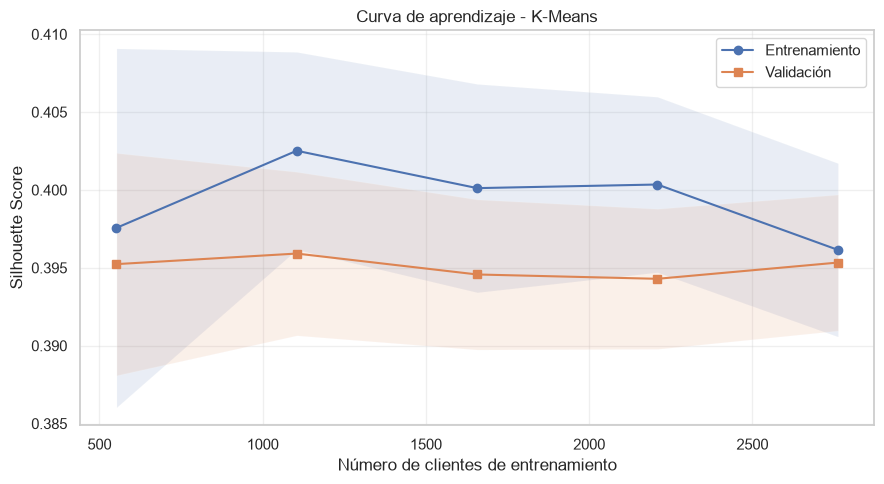

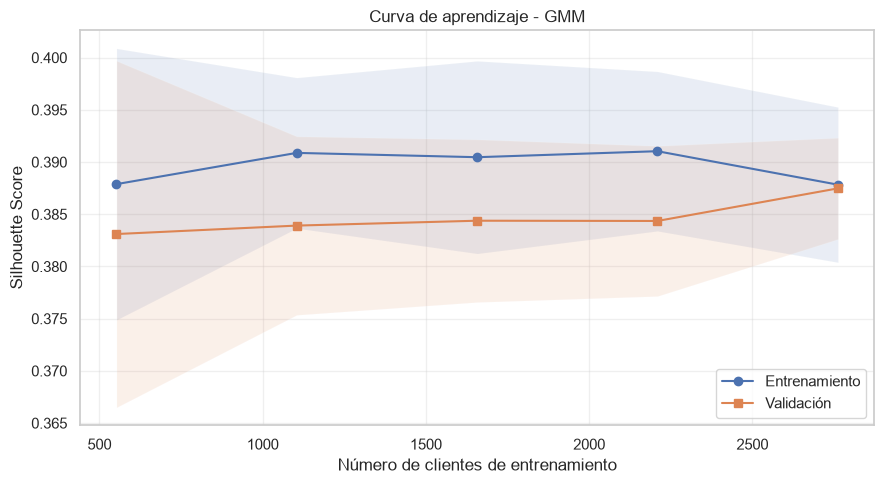

In [45]:
import matplotlib.pyplot as plt

for algoritmo in ["K-Means", "GMM"]:

    datos = resumen_curvas[
        resumen_curvas["Algoritmo"] == algoritmo
    ].sort_values("NTrain")

    x = datos["NTrain"].to_numpy()
    train = datos["TrainMedio"].to_numpy()
    val = datos["ValMedio"].to_numpy()

    train_std = datos["TrainStd"].fillna(0).to_numpy()
    val_std = datos["ValStd"].fillna(0).to_numpy()

    plt.figure(figsize=(9, 5))

    plt.plot(
        x, train,
        marker="o",
        label="Entrenamiento"
    )

    plt.plot(
        x, val,
        marker="s",
        label="Validación"
    )

    plt.fill_between(
        x,
        train - train_std,
        train + train_std,
        alpha=0.12
    )

    plt.fill_between(
        x,
        val - val_std,
        val + val_std,
        alpha=0.12
    )

    plt.title(
        f"Curva de aprendizaje - {algoritmo}"
    )

    plt.xlabel("Número de clientes de entrenamiento")
    plt.ylabel("Silhouette Score")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Conclusiones del análisis de las curvas de aprendizaje

Las curvas de aprendizaje permitieron analizar el comportamiento de K-Means y Gaussian Mixture Models ante diferentes tamaños del conjunto de entrenamiento, comprendidos entre aproximadamente 552 y 2.762 clientes.

K-Means presentó puntuaciones de Silhouette cercanas a 0,40 tanto en entrenamiento como en validación, evidenciando una variabilidad reducida y diferencias pequeñas entre ambas curvas. Por su parte, GMM alcanzó puntuaciones próximas a 0,39, mostrando una tendencia hacia la convergencia entre las métricas de entrenamiento y validación.

En ambos algoritmos se observó una estabilización de las puntuaciones conforme aumentó la cantidad de datos, sin mejoras sustanciales en la calidad del agrupamiento dentro del rango evaluado.

Estos resultados complementan la optimización de hiperparámetros y la comparación estadística previa, respaldando la elección provisional de K-Means como algoritmo principal. Sin embargo, la estabilidad observada corresponde a métricas internas de clustering y no garantiza por sí sola que los segmentos obtenidos sean estables individualmente o comercialmente útiles.

## 11. Evaluación final sobre el conjunto de reserva

In [46]:
# Entrenar ambos modelos con todos los datos de desarrollo

modelos_finales = {}

for algoritmo in ["K-Means", "GMM"]:

    config = configs_finales[algoritmo]

    pipeline = construir_pipeline_cv(config)

    pipeline.fit(X_desarrollo)

    modelos_finales[algoritmo] = pipeline

    seleccion = pipeline.named_steps["selection"]

    print(f"\n{algoritmo}")
    print("Clientes de entrenamiento:", len(X_desarrollo))

    print(
        "Características seleccionadas:",
        list(seleccion.get_feature_names_out(features))
    )


K-Means
Clientes de entrenamiento: 3453
Características seleccionadas: [np.str_('Recency'), np.str_('Monetary'), np.str_('Frequency'), np.str_('ProductDiversity')]

GMM
Clientes de entrenamiento: 3453
Características seleccionadas: [np.str_('Recency'), np.str_('Monetary'), np.str_('Frequency'), np.str_('ProductDiversity')]


In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import numpy as np
import pandas as pd

# Representación común para evaluar ambos algoritmos
# Ajustar únicamente utilizando los datos de desarrollo

preprocesamiento_comun = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

preprocesamiento_comun.fit(X_desarrollo)

X_reserva_comun = (
    preprocesamiento_comun.transform(X_reserva)
)

resultados_finales = []
etiquetas_reserva = pd.DataFrame(index=X_reserva.index)

for algoritmo, pipeline in modelos_finales.items():

    etiquetas = pipeline.predict(X_reserva)

    etiquetas_reserva[algoritmo] = etiquetas

    grupos, conteos = np.unique(
        etiquetas,
        return_counts=True
    )

    k_esperado = int(configs_finales[algoritmo]["k"])

    valido = (
        len(grupos) == k_esperado
        and conteos.min() / len(etiquetas) >= 0.01
    )

    if valido:

        silhouette = silhouette_score(
            X_reserva_comun,
            etiquetas
        )

        davies = davies_bouldin_score(
            X_reserva_comun,
            etiquetas
        )

        calinski = calinski_harabasz_score(
            X_reserva_comun,
            etiquetas
        )

    else:
        silhouette = np.nan
        davies = np.nan
        calinski = np.nan

    resultados_finales.append({
        "Algoritmo": algoritmo,
        "Silhouette": silhouette,
        "DaviesBouldin": davies,
        "CalinskiHarabasz": calinski,
        "ClustersObservados": len(grupos),
        "GrupoMinimo": int(conteos.min())
    })

    print(f"\n=== {algoritmo} ===")

    for grupo, cantidad in zip(grupos, conteos):

        porcentaje = 100 * cantidad / len(etiquetas)

        print(
            f"Cluster {grupo}: "
            f"{cantidad} clientes ({porcentaje:.2f}%)"
        )

resultados_finales = pd.DataFrame(resultados_finales)

print("\n=== RESULTADOS FINALES ===")
display(resultados_finales.round(4))


=== K-Means ===
Cluster 0: 518 clientes (59.95%)
Cluster 1: 346 clientes (40.05%)

=== GMM ===
Cluster 0: 496 clientes (57.41%)
Cluster 1: 368 clientes (42.59%)

=== RESULTADOS FINALES ===


,Algoritmo,Silhouette,DaviesBouldin,CalinskiHarabasz,ClustersObservados,GrupoMinimo
0,K-Means,0.41,0.92,830.10,2,346
1,GMM,0.40,0.93,817.98,2,368


### Conclusiones de la evaluación final

La evaluación sobre el conjunto de reserva se realizó utilizando 864 clientes que no participaron en la optimización de hiperparámetros ni en el entrenamiento de los modelos.

K-Means alcanzó un Silhouette Score de 0,41, un índice Davies-Bouldin de 0,92 y un índice Calinski-Harabasz de 830,10. Por su parte, Gaussian Mixture Models obtuvo valores de 0,40, 0,93 y 817,98, respectivamente.

Estos resultados favorecieron ligeramente a K-Means y fueron consistentes con el comportamiento observado durante la validación cruzada. Asimismo, ambos algoritmos generaron dos grupos con distribuciones de clientes razonables, sin segmentos excesivamente pequeños.

En consecuencia, se seleccionó K-Means como algoritmo final para la segmentación de clientes. Aunque su ventaja cuantitativa frente a GMM es reducida, presentó resultados consistentemente favorables durante las diferentes etapas experimentales.

La siguiente fase se orienta a visualizar los agrupamientos mediante t-SNE e interpretar sus características comerciales, con el propósito de determinar si los segmentos identificados representan patrones de compra diferenciados y útiles para la toma de decisiones.

## 12. Segmentación final e interpretación de clientes

In [48]:
# Recuperar configuración final de K-Means
config_kmeans = configs_finales["K-Means"].copy()

# Construir y entrenar el pipeline definitivo
pipeline_segmentacion = construir_pipeline_cv(
    config_kmeans
)

pipeline_segmentacion.fit(X)

# Predecir clusters para todos los clientes
etiquetas_finales = pipeline_segmentacion.predict(X)

# Transformar características para visualizaciones
X_final_transformado = (
    pipeline_segmentacion[:-1].transform(X)
)

print("Clientes segmentados:", len(X))
print("Dimensiones transformadas:", X_final_transformado.shape)

# Distribución final de clusters
clusters, conteos = np.unique(
    etiquetas_finales,
    return_counts=True
)

for cluster, cantidad in zip(clusters, conteos):
    porcentaje = 100 * cantidad / len(X)

    print(
        f"Cluster {cluster}: "
        f"{cantidad} clientes ({porcentaje:.2f}%)"
    )

Clientes segmentados: 4317
Dimensiones transformadas: (4317, 4)
Cluster 0: 2579 clientes (59.74%)
Cluster 1: 1738 clientes (40.26%)


In [49]:
# Recuperar características originales de los clientes
df_segmentos = rfm_modelo.loc[
    X.index,
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "AvgTicket",
        "ProductDiversity"
    ]
].copy()

# Incorporar las etiquetas finales
df_segmentos["Cluster"] = etiquetas_finales

print("Clientes segmentados:", len(df_segmentos))

display(df_segmentos.head())

Clientes segmentados: 4317


,CustomerID,Recency,Frequency,Monetary,AvgTicket,ProductDiversity,Cluster
0,"12,347.00",2,7,"4,310.00",615.71,103,1
1,"12,348.00",75,4,"1,797.24",449.31,22,0
2,"12,349.00",19,1,"1,757.55","1,757.55",73,1
3,"12,350.00",310,1,334.40,334.40,17,0
4,"12,352.00",36,8,"1,545.41",193.18,59,1


In [50]:
perfil_clusters = (
    df_segmentos
    .groupby("Cluster")
    .agg(
        Clientes=("CustomerID", "count"),
        RecencyMediana=("Recency", "median"),
        FrequencyMediana=("Frequency", "median"),
        MonetaryMediana=("Monetary", "median"),
        MonetaryMedia=("Monetary", "mean"),
        TicketMediano=("AvgTicket", "median"),
        DiversidadMediana=("ProductDiversity", "median"),
        GastoTotal=("Monetary", "sum")
    )
)

perfil_clusters["PorcentajeClientes"] = (
    100 * perfil_clusters["Clientes"]
    / perfil_clusters["Clientes"].sum()
)

perfil_clusters["PorcentajeGasto"] = (
    100 * perfil_clusters["GastoTotal"]
    / perfil_clusters["GastoTotal"].sum()
)

display(perfil_clusters.round(2))

,Clientes,RecencyMediana,FrequencyMediana,MonetaryMediana,MonetaryMedia,TicketMediano,DiversidadMediana,GastoTotal,PorcentajeClientes,PorcentajeGasto
Cluster,,,,,,,,,,
0,2579,96.00,1.00,347.75,472.23,230.51,20.00,"1,217,890.14",59.74,14.65
1,1738,18.00,5.00,"1,930.78","4,082.51",344.18,89.00,"7,095,404.81",40.26,85.35


## 13. Visualización bidimensional mediante t-SNE

In [51]:
from sklearn.manifold import TSNE

# Reducir las características procesadas a dos dimensiones
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(
    X_final_transformado
)

# Crear DataFrame para visualizar
df_tsne = pd.DataFrame(
    X_tsne,
    columns=["TSNE_1", "TSNE_2"],
    index=X.index
)

df_tsne["Cluster"] = etiquetas_finales

print("Dimensiones t-SNE:", df_tsne.shape)

display(df_tsne.head())

Dimensiones t-SNE: (4317, 3)


,TSNE_1,TSNE_2,Cluster
0,42.60,-31.67,1
1,19.98,31.22,0
2,-27.33,10.47,1
3,-74.37,11.96,0
4,39.85,-4.38,1


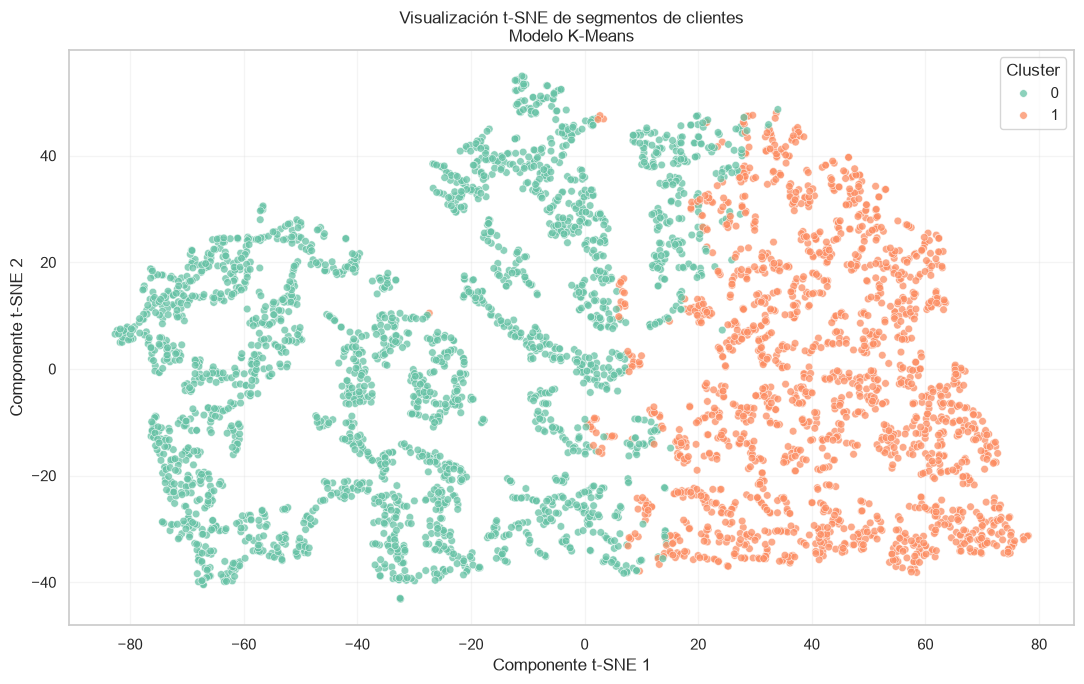

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_tsne,
    x="TSNE_1",
    y="TSNE_2",
    hue="Cluster",
    palette="Set2",
    s=30,
    alpha=0.75
)

plt.title(
    "Visualización t-SNE de segmentos de clientes\n"
    "Modelo K-Means"
)

plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")

plt.legend(title="Cluster")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Conclusiones de la segmentación final

La aplicación del algoritmo K-Means permitió identificar dos segmentos diferenciados entre los 4.317 clientes analizados, utilizando características relacionadas con recencia, frecuencia, gasto monetario neto y diversidad de productos.

El primer segmento, denominado **clientes ocasionales o de menor actividad**, comprende 2.579 clientes (59,74 %) y representa únicamente el 14,65 % del gasto neto total. Sus principales características incluyen una frecuencia mediana de una compra, una recencia mediana de 96 días y un gasto mediano de £347,75.

El segundo segmento, denominado **clientes frecuentes de alto valor**, agrupa 1.738 clientes (40,26 %) y concentra el 85,35 % del gasto neto analizado. Presenta una frecuencia mediana de cinco compras, una recencia mediana de 18 días y un gasto mediano de £1.930,78.

La visualización mediante t-SNE permitió observar una separación visual apreciable entre ambos grupos, aunque también se identificaron regiones de superposición. Esta representación complementa los resultados cuantitativos, pero no constituye por sí sola una prueba de la calidad del agrupamiento.

En conclusión, la segmentación obtenida demuestra la utilidad del aprendizaje no supervisado para explorar comportamientos de consumo y apoyar decisiones comerciales basadas en datos. Sin embargo, las acciones propuestas requieren validación adicional antes de atribuirles efectos sobre las ventas o la retención de clientes.

## 14. Conclusiones generales

El presente proyecto permitió implementar una metodología de aprendizaje automático no supervisado para segmentar clientes de comercio electrónico a partir de sus comportamientos de compra.

A partir de 541.909 registros transaccionales, se realizó un proceso de exploración, limpieza, tratamiento de devoluciones e ingeniería de características, obteniendo finalmente 4.317 clientes aptos para la segmentación.

El análisis exploratorio evidenció distribuciones asimétricas, valores extremos y correlaciones relevantes entre variables. La aplicación de transformaciones logarítmicas, estandarización y selección de características permitió desarrollar pipelines reproducibles para los algoritmos K-Means y Gaussian Mixture Models.

La optimización de hiperparámetros mediante validación cruzada repetida favoreció configuraciones de dos clusters para ambos algoritmos. Posteriormente, la comparación estadística mediante validación cruzada anidada mostró una ventaja consistente, aunque pequeña, de K-Means. La prueba de Wilcoxon produjo un p-valor exploratorio de 0,001953, cuya interpretación se encuentra limitada por la dependencia entre las particiones repetidas.

En la evaluación independiente, K-Means obtuvo un Silhouette Score de 0,41, frente a 0,40 de GMM, respaldando su selección como algoritmo final.

La segmentación identificó dos grupos de clientes con comportamientos diferenciados. El segmento de clientes frecuentes de alto valor representa el 40,26 % de los clientes y concentra el 85,35 % del gasto neto analizado, mientras que el segmento de menor actividad representa el 59,74 % de los clientes y aporta el 14,65 % del gasto neto.

Estos hallazgos demuestran que las técnicas de clustering pueden contribuir a identificar patrones de consumo relevantes y apoyar el diseño de estrategias comerciales diferenciadas.

Como limitaciones, se reconoce la influencia potencial de los registros duplicados, la ausencia de información sobre rentabilidad y la dependencia de métricas internas para evaluar los agrupamientos. Como trabajo futuro, se propone analizar la estabilidad temporal de los segmentos y evaluar experimentalmente estrategias de fidelización y reactivación.